In [82]:
!pip install torch-geometric

In [83]:
import torch


class HybridLoss(torch.nn.Module):
    def __init__(self, lamd=1e-1, spatial_tv=False, spectral_tv=False):
        super(HybridLoss, self).__init__()
        self.lamd = lamd
        self.use_spatial_TV = spatial_tv
        self.use_spectral_TV = spectral_tv
        self.fidelity = torch.nn.L1Loss()
        self.spatial = TVLoss(weight=1e-3)
        self.spectral = TVLossSpectral(weight=1e-3)

    def forward(self, y, gt):
        loss = self.fidelity(y, gt)
        spatial_TV = 0.0
        spectral_TV = 0.0
        if self.use_spatial_TV:
            spatial_TV = self.spatial(y)
        if self.use_spectral_TV:
            spectral_TV = self.spectral(y)
        total_loss = loss + spatial_TV + spectral_TV
        return total_loss


# from https://github.com/jxgu1016/Total_Variation_Loss.pytorch with slight modifications
class TVLoss(torch.nn.Module):
    def __init__(self, weight=1.0):
        super(TVLoss, self).__init__()
        self.TVLoss_weight = weight

    def forward(self, x):
        batch_size = x.size()[0]
        h_x = x.size()[2]
        w_x = x.size()[3]
        count_h = self._tensor_size(x[:, :, 1:, :])
        count_w = self._tensor_size(x[:, :, :, 1:])
        # h_tv = torch.abs(x[:, :, 1:, :] - x[:, :, :h_x - 1, :]).sum()
        # w_tv = torch.abs(x[:, :, :, 1:] - x[:, :, :, :w_x - 1]).sum()
        h_tv = torch.pow((x[:, :, 1:, :] - x[:, :, :h_x - 1, :]), 2).sum()
        w_tv = torch.pow((x[:, :, :, 1:] - x[:, :, :, :w_x - 1]), 2).sum()
        return self.TVLoss_weight * (h_tv / count_h + w_tv / count_w) / batch_size

    def _tensor_size(self, t):
        return t.size()[1] * t.size()[2] * t.size()[3]


class TVLossSpectral(torch.nn.Module):
    def __init__(self, weight=1.0):
        super(TVLossSpectral, self).__init__()
        self.TVLoss_weight = weight

    def forward(self, x):
        batch_size = x.size()[0]
        c_x = x.size()[1]
        count_c = self._tensor_size(x[:, 1:, :, :])
        # c_tv = torch.abs((x[:, 1:, :, :] - x[:, :c_x - 1, :, :])).sum()
        c_tv = torch.pow((x[:, 1:, :, :] - x[:, :c_x - 1, :, :]), 2).sum()
        return self.TVLoss_weight * 2 * (c_tv / count_c) / batch_size

    def _tensor_size(self, t):
        return t.size()[1] * t.size()[2] * t.size()[3]


In [84]:
import numpy
import numpy as np
import scipy.io as sio
import torch.nn.functional as F
from skimage.transform import rescale
import matplotlib.pyplot as plt

def create_HS_list(load_pan_dir, t, patchsize_HSI):
    print('===>>>处理{}时刻图片'.format(t))
    # 读入图片
    datas = sio.loadmat(load_pan_dir)
    if(t=='t2'):
        img = np.array(datas['T2'][...], dtype=np.float32)
    elif(t=='t1'):
        img = np.array(datas['T1'][...], dtype=np.float32)
    else:
        exit()
    img = normalize_data(img)
    bands = img.shape[2]

    # 填充到423x144
    temp = img[:, :, 0]  # 420x140
    temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
    [h_pad, w_pad] = temp2.shape
    img_pad = np.empty((h_pad, w_pad, bands), dtype='float32')
    for i in range(bands):
        temp = img[:, :, i]
        temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
        img_pad[:, :, i] = temp2
    print('填充后原图片尺寸:',img_pad.shape)

    # img_pad = img
    # print('不填充图片')

    height, width = img_pad.shape[0], img_pad.shape[1]

    # 原图的缩放
    img_lr = rescale(img_pad, (1 / 3, 1 / 3, 1), order=3, mode='edge', anti_aliasing=True)
    # 切patch（多光谱）
    # 先给第一个维度打padding，确定打完padding的矩阵的大小后，建立一个[H,W,C]的空矩阵，再用循环给所有维度打padding
    temp = img_lr[:, :, 0]
    temp_mid = img_pad[:, :, 0]
    pad_width = np.floor(patchsize_HSI / 2)
    pad_width = np.int32(pad_width)
    pad_width_mid = np.floor(patchsize_HSI * 3 / 2)
    pad_width_mid = np.int32(pad_width_mid)
    temp2 = np.pad(temp, pad_width, 'symmetric')
    temp2_mid = np.pad(temp_mid, pad_width_mid-1, 'symmetric')
    [h_pad, w_pad] = temp2.shape
    [h_pad_mid, w_pad_mid] = temp2_mid.shape
    data_HSI_pad = np.empty((h_pad, w_pad, bands), dtype='float32')
    data_mid_pad = np.empty((h_pad_mid, w_pad_mid, bands), dtype='float32')
    for i in range(bands):
        temp = img_lr[:, :, i]
        temp_mid = img_pad[:, :, i]
        temp2 = np.pad(temp, pad_width, 'symmetric')
        temp2_mid = np.pad(temp_mid, pad_width_mid-1, 'symmetric')
        data_HSI_pad[:, :, i] = temp2
        data_mid_pad[:, :, i] = temp2_mid
    print('二次填充后图片尺寸:',data_mid_pad.shape)
    # 构建高光谱patch序列
    img_list_LRHS=[]
    img_list_mid =[]
    k = 0
    for i in range(int(height/3)):
        for j in range(int(width/3)):
            # x是打了padding的高光谱
            # 取第i个训练patch，取一个立方体
            patch = data_HSI_pad[(i):(i + 2 * pad_width + 1),
                    (j):(j + 2 * pad_width + 1),:]
            patch_mid = data_mid_pad[(i*3):(i*3 + 2 * pad_width_mid + 1),
                    (j*3):(j*3 + 2 * pad_width_mid + 1),:]
            # print(patch.shape,patch_mid.shape)
            img_list_LRHS.append(patch)
            img_list_mid.append(patch_mid)
            k = k + 1
    print('每个高光谱低分辨率图的patch的尺寸：', img_list_LRHS[0].shape)
    print('每个高光谱高分辨率图的patch的尺寸：', img_list_mid[0].shape)

    # 将pad后的原图构建为PAN
    img_pan = np.mean(img_pad[:,:,:27], axis=2)
    # img_pan = mat2gray(img_pan)

    # 切patch（PAN）
    pad_width = np.floor(patchsize_HSI * 3 / 2)
    pad_width = np.int32(pad_width)
    img_pan = np.pad(img_pan, pad_width-1, 'symmetric')
    # 构建PAN patch序列
    img_list_PAN=[]
    k = 0
    for i in range(int(height/3)):
        for j in range(int(width/3)):
            # x是打了padding的高光谱
            # 取第i个训练patch，取一个立方体
            patch = img_pan[(3*i):(3*i + 2 * pad_width + 1),
                    (3*j):(3*j + 2 * pad_width + 1)]
            img_list_PAN.append(patch)
            k = k + 1
    print('每个PAN图的patch的尺寸：', img_list_PAN[0].shape)
    # print('每类各', k, '个patch已切完')
    return img_list_LRHS, img_list_PAN, img_list_mid

def create_HS_list_224(load_pan_dir, t, patchsize_HSI):
    print('===>>>处理{}时刻图片'.format(t))
    # 读入图片
    datas = sio.loadmat(load_pan_dir)
    if(t=='t2'):
        img = np.array(datas['T2'][...], dtype=np.float32)
    elif(t=='t1'):
        img = np.array(datas['T1'][...], dtype=np.float32)
    else:
        exit()

    if load_pan_dir == './data/Bay.mat':
        img = normalize_data_2(img)
    else:
        img = normalize_data(img)
    bands = img.shape[2]

    # 填充到423x144
    temp = img[:, :, 0]  # 420x140
    temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
    [h_pad, w_pad] = temp2.shape
    img_pad = np.empty((h_pad, w_pad, bands), dtype='float32')
    for i in range(bands):
        temp = img[:, :, i]
        temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
        img_pad[:, :, i] = temp2
    print('填充后原图片尺寸:',img_pad.shape)

    # img_pad = img
    # print('不填充图片')

    height, width = img_pad.shape[0], img_pad.shape[1]

    # 原图的缩放
    img_lr = rescale(img_pad, (1 / 3, 1 / 3, 1), order=3, mode='edge', anti_aliasing=True)
    # 切patch（多光谱）
    # 先给第一个维度打padding，确定打完padding的矩阵的大小后，建立一个[H,W,C]的空矩阵，再用循环给所有维度打padding
    temp = img_lr[:, :, 0]
    temp_mid = img_pad[:, :, 0]
    pad_width = np.floor(patchsize_HSI / 2)
    pad_width = np.int32(pad_width)
    pad_width_mid = np.floor(patchsize_HSI * 3 / 2)
    pad_width_mid = np.int32(pad_width_mid)
    temp2 = np.pad(temp, pad_width, 'symmetric')
    temp2_mid = np.pad(temp_mid, pad_width_mid-1, 'symmetric')
    [h_pad, w_pad] = temp2.shape
    [h_pad_mid, w_pad_mid] = temp2_mid.shape
    data_HSI_pad = np.empty((h_pad, w_pad, bands), dtype='float32')
    data_mid_pad = np.empty((h_pad_mid, w_pad_mid, bands), dtype='float32')
    for i in range(bands):
        temp = img_lr[:, :, i]
        temp_mid = img_pad[:, :, i]
        temp2 = np.pad(temp, pad_width, 'symmetric')
        temp2_mid = np.pad(temp_mid, pad_width_mid-1, 'symmetric')
        data_HSI_pad[:, :, i] = temp2
        data_mid_pad[:, :, i] = temp2_mid
    print('二次填充后图片尺寸:',data_mid_pad.shape)
    # 构建高光谱patch序列
    img_list_LRHS=[]
    img_list_mid =[]
    k = 0
    for i in range(int(height/3)):
        for j in range(int(width/3)):
            # x是打了padding的高光谱
            # 取第i个训练patch，取一个立方体
            patch = data_HSI_pad[(i):(i + 2 * pad_width + 1),
                    (j):(j + 2 * pad_width + 1),:]
            patch_mid = data_mid_pad[(i*3):(i*3 + 2 * pad_width_mid + 1),
                    (j*3):(j*3 + 2 * pad_width_mid + 1),:]
            # print(patch.shape,patch_mid.shape)
            img_list_LRHS.append(patch)
            img_list_mid.append(patch_mid)
            k = k + 1
    print('每个高光谱低分辨率图的patch的尺寸：', img_list_LRHS[0].shape)
    print('每个高光谱高分辨率图的patch的尺寸：', img_list_mid[0].shape)

    # 将pad后的原图构建为RGB
    # img_R = np.mean(img_pad[:,:,0:75], axis=2)
    # img_R = mat2gray(img_R)
    # img_G = np.mean(img_pad[:,:,75:150], axis=2)
    # img_G = mat2gray(img_G)
    # img_B = np.mean(img_pad[:,:,150:224], axis=2)
    # img_B = mat2gray(img_B)
    img_R = img_pad[:,:,10]
    img_G = img_pad[:,:,20]
    img_B = img_pad[:,:,35]

    # 切patch（PAN）
    pad_width = np.floor(patchsize_HSI * 3 / 2)
    pad_width = np.int32(pad_width)
    img_R = np.pad(img_R, pad_width-1, 'symmetric')
    img_G = np.pad(img_G, pad_width-1, 'symmetric')
    img_B = np.pad(img_B, pad_width-1, 'symmetric')
    # 构建PAN patch序列
    img_list_PAN=[]
    k = 0
    for i in range(int(height/3)):
        for j in range(int(width/3)):
            # x是打了padding的高光谱
            # 取第i个训练patch，取一个立方体
            patch1 = img_R[(3*i):(3*i + 2 * pad_width + 1),
                    (3*j):(3*j + 2 * pad_width + 1)]
            patch2 = img_G[(3*i):(3*i + 2 * pad_width + 1),
                    (3*j):(3*j + 2 * pad_width + 1)]
            patch3 = img_B[(3*i):(3*i + 2 * pad_width + 1),
                    (3*j):(3*j + 2 * pad_width + 1)]
            patch = np.stack([patch1,patch2,patch3],axis=2)
            img_list_PAN.append(patch)
            k = k + 1
    print('每个PAN图的patch的尺寸：', img_list_PAN[0].shape)
    # print('每类各', k, '个patch已切完')
    return img_list_LRHS, img_list_PAN, img_list_mid


def create_gt(dir_original_img):
    k = 0
    datas = sio.loadmat(dir_original_img)
    img = np.array(datas['GT'][...], dtype=np.float32) # 420x140
    img = np.pad(img, ((0, 0), (0, 1)), 'symmetric')
    # img = np.pad(img, ((1, 2), (2, 2)), 'symmetric')
    height,width = img.shape
    # gt_list = torch.zeros(int(height/3)*int(width/3))
    gt_list = []
    for i in range(int(height/3)):
        for j in range(int(width/3)):
            # x是打了padding的高光谱
            # 取第i个训练patch，取一个立方体
            if img[i*3+1,j*3+1] == 1 :
            # if img[i*3,j*3] == 1 :
                #gt_list[k] = 1
                gt_list.append(1)
            elif img[i*3+1,j*3+1] == 0 :
            # elif img[i*3,j*3] == 0 :
                # gt_list[k] = -1
                gt_list.append(0)
            else:
                gt_list.append(2)
            k = k + 1
    high = i+1
    print('读入真实标签数：',k,'图片高度：',high,'图片宽度：',j+1)
    return gt_list,high

def create_pseudo_label(dir,need_numpy=False):
    k = 0
    datas = sio.loadmat(dir)
    img = np.array(datas['result'][...], dtype=np.float32)
    plt.imshow(img)
    plt.suptitle(dir)
    plt.show()
    height,width = img.shape
    label_list = []
    for i in range(int(height)):
        for j in range(int(width)):
            # x是打了padding的高光谱
            # 取第i个训练patch，取一个立方体
            if img[i,j]==1 :
                label_list.append(1)
            elif img[i,j] == 0:
                label_list.append(0)
            else:
                label_list.append(2)
            k = k + 1
    # print('生成伪标签数：',k)
    if need_numpy:
        return label_list,img
    else:
        return label_list

def mat2gray(matrix):
    """将矩阵中的像素值范围映射到 [0, 1] 之间的范围"""
    min_val = np.min(matrix)
    max_val = np.max(matrix)
    if min_val != max_val:
        normalized = (matrix - min_val) / (max_val - min_val)
    else:
        normalized = matrix
    return normalized

def normalize_data(data):
    # 获取每个特征的最大值和最小值
    data2 = data.reshape(data.shape[0]*data.shape[1],data.shape[2])
    # min_vals = np.min(data2, axis=0)
    # max_vals = np.max(data2, axis=0)
    min_vals = np.min(data2)
    max_vals = np.max(data2)
    # 将数据减去最小值，再除以最大值和最小值的差
    normalized_data2 = (data2 - min_vals) / (max_vals - min_vals)
    normalized_data = normalized_data2.reshape(data.shape[0],data.shape[1],data.shape[2])
    return normalized_data

def normalize_data_2(data):
    # 获取每个特征的最大值和最小值
    data2 = data.reshape(data.shape[0]*data.shape[1],data.shape[2])
    min_vals = np.min(data2, axis=0)
    max_vals = np.max(data2, axis=0)
    # 将数据减去最小值，再除以最大值和最小值的差
    normalized_data2 = (data2 - min_vals) / (max_vals - min_vals)
    normalized_data = normalized_data2.reshape(data.shape[0],data.shape[1],data.shape[2])
    return normalized_data





import os

def create_test_mat_file(file_path, data):
    sio.savemat(file_path, {'T1': data, 'T2': data})


# 测试 create_HS_list 函数
def test_create_HS_list():
    # 创建一个简单的测试数据
    test_data = np.random.rand(420, 140, 224).astype(np.float32)

    # 保存测试数据到 .mat 文件
    test_mat_file = './test_data.mat'
    create_test_mat_file(test_mat_file, test_data)
    PAN_path = '/media/xd132/E1/WHB/xiugao/data/Liyukou/T1_RGB.mat'

    # 调用 create_HS_list 函数
    img_list_LRHS, img_list_PAN, img_list_mid = create_HS_list(test_mat_file, 't1', 3)

    # 打印结果
    print('LRHS Patches:', len(img_list_LRHS))
    print('PAN Patches:', len(img_list_PAN))
    print('Mid Patches:', len(img_list_mid))
    print('First LRHS Patch Shape:', img_list_LRHS[0].shape)
    print('First PAN Patch Shape:', img_list_PAN[0].shape)
    print('First Mid Patch Shape:', img_list_mid[0].shape)

    # 删除测试文件
    # os.remove(test_mat_file)


# 运行测试样例
if __name__ == '__main__':
    test_create_HS_list()

===>>>处理t1时刻图片
填充后原图片尺寸: (420, 141, 224)
二次填充后图片尺寸: (426, 147, 224)
每个高光谱低分辨率图的patch的尺寸： (3, 3, 224)
每个高光谱高分辨率图的patch的尺寸： (9, 9, 224)
每个PAN图的patch的尺寸： (9, 9)
LRHS Patches: 6580
PAN Patches: 6580
Mid Patches: 6580
First LRHS Patch Shape: (3, 3, 224)
First PAN Patch Shape: (9, 9)
First Mid Patch Shape: (9, 9, 224)


In [85]:
import os
import scipy.io as sio
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset


class AllDataset(Dataset):
    def __init__(self,patch_dir):
        # patch_folders = [os.path.join(patch_dir, x) for x in os.listdir(patch_dir)]
        # self.patch_files = []
        # for i in range(len(patch_folders)):
        #     self.patch_files.extend([os.path.join(patch_folders[i], x) for x in os.listdir(patch_folders[i])])
        self.patch_files = [os.path.join(patch_dir, x) for x in os.listdir(patch_dir)]

    def __len__(self):
        return len(self.patch_files)

    def __getitem__(self, index):
        load_dir = self.patch_files[index]
        data = sio.loadmat(load_dir)
        hs_t1 = np.array(data['hs_t1'][...])
        hs_t2 = np.array(data['hs_t2'][...])
        pan_t1 = np.array(data['pan_t1'][...])
        pan_t2 = np.array(data['pan_t2'][...])
        arr = np.array(data['arr']).squeeze()
        list_gt = np.array(data['gt']).squeeze()
        pseudo_label = np.array(data['pseudo_label']).squeeze()
        # upsample_t1 = np.array(data['upsample_t1'][...])
        return hs_t1, hs_t2, pan_t1, pan_t2, list_gt, arr, pseudo_label,index

class AllDataset224(Dataset):
    def __init__(self,patch_dir):
        # patch_folders = [os.path.join(patch_dir, x) for x in os.listdir(patch_dir)]
        # self.patch_files = []
        # for i in range(len(patch_folders)):
        #     self.patch_files.extend([os.path.join(patch_folders[i], x) for x in os.listdir(patch_folders[i])])
        self.patch_files = [os.path.join(patch_dir, x) for x in os.listdir(patch_dir)]

    def __len__(self):
        return len(self.patch_files)

    def __getitem__(self, index):
        load_dir = self.patch_files[index]
        data = sio.loadmat(load_dir)
        hs_t1 = np.array(data['hs_t1'][...])
        hs_t2 = np.array(data['hs_t2'][...])
        pan_t1 = np.array(data['pan_t1'][...])
        pan_t2 = np.array(data['pan_t2'][...])
        arr = np.array(data['arr']).squeeze()
        arr2 = np.array(data['arr2']).squeeze()
        list_gt = np.array(data['gt']).squeeze()
        pseudo_label = np.array(data['pseudo_label']).squeeze()
        # upsample_t1 = np.array(data['upsample_t1'][...])
        return hs_t1, hs_t2, pan_t1, pan_t2, list_gt, arr, pseudo_label,index,arr2

In [86]:
import torch
import torch.nn as nn

# UNet with PixelShuffle & MaxPool

class double_conv(nn.Module):
    def __init__(self, input_features, output_features, negative_slope=0, p_drop=0):
        super(double_conv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(input_features, output_features, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(output_features),
            nn.LeakyReLU(negative_slope=negative_slope, inplace=True),
            nn.Dropout2d(p=p_drop),
            nn.Conv2d(output_features, output_features, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(output_features),
            nn.LeakyReLU(negative_slope=negative_slope, inplace=True)
        )
    def forward(self, x):
        x = self.conv(x)
        return x

class down_block(nn.Module):
    def __init__(self, input_features, output_features, negative_slope=0, p_drop=0):
        super(down_block, self).__init__()
        self.down = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(p=p_drop),
            double_conv(input_features, output_features, negative_slope, p_drop)
        )
    def forward(self, x):
        x = self.down(x)
        return x

class up_block(nn.Module):
    def __init__(self, input_features, output_features, negative_slope=0, p_drop=0):
        super(up_block, self).__init__()
        self.up = nn.PixelShuffle(upscale_factor=2)
        self.conv = nn.Sequential(
            nn.Dropout2d(p=p_drop),
            double_conv(int(input_features/4+output_features), output_features, negative_slope, p_drop)
        )
    def forward(self, x, x_pre):
        x = self.up(x)
        x = torch.cat((x, x_pre), 1)
        x = self.conv(x)
        return x

class SpeSRModel(nn.Module):
    def __init__(self, input_features, output_features, negative_slope=0, p_drop=0):
        super(SpeSRModel, self).__init__()
        self.in_conv = double_conv(input_features, 64, negative_slope, p_drop)
        self.in_conv1 = nn.Conv2d(64, 64, kernel_size=2, padding=3, stride=1)
        self.down1 = down_block(64, 128, negative_slope, p_drop) # W/2
        self.down2 = down_block(128, 256, negative_slope, p_drop) # W/4
        self.down3 = down_block(256, 512, negative_slope, p_drop) # W/8
        self.bottleneck = down_block(512, 1024, negative_slope, p_drop) # W/16
        self.up1 = up_block(1024, 512, negative_slope, p_drop) # W/8
        self.up2 = up_block(512, 256, negative_slope, p_drop) # W/4
        self.up3 = up_block(256, 128, negative_slope, p_drop) # W/2
        self.out_conv = up_block(128, 64, negative_slope, p_drop) # W
        self.out_conv1 = nn.Conv2d(64, 64, kernel_size=6, padding=0, stride=1)
        self.out = nn.Conv2d(64, output_features, kernel_size=1, padding=0, bias=False)
    def forward(self, x):
        conv = self.in_conv(x) # W 64
        conv = self.in_conv1(conv)
        down1 = self.down1(conv) # W/2 128
        down2 = self.down2(down1) # W/4 256
        down3 = self.down3(down2) # W/8 512
        bottleneck = self.bottleneck(down3) # W/16 1024
        up = self.up1(bottleneck, down3) # W/8 512
        up = self.up2(up, down2) # W/4 256
        up = self.up3(up, down1) # W/2 128
        up = self.out_conv(up, conv) # W 64
        up = self.out_conv1(up)
        out = self.out(up)

        return out

class SpeSRModel224(nn.Module):
    def __init__(self, input_features, output_features, negative_slope=0, p_drop=0):
        super(SpeSRModel224, self).__init__()
        self.in_conv = double_conv(input_features, 64, negative_slope, p_drop)
        self.in_conv1 = nn.Conv2d(64, 64, kernel_size=2, padding=3, stride=1)
        self.down1 = down_block(64, 128, negative_slope, p_drop) # W/2
        self.down2 = down_block(128, 256, negative_slope, p_drop) # W/4
        self.down3 = down_block(256, 512, negative_slope, p_drop) # W/8
        self.bottleneck = down_block(512, 1024, negative_slope, p_drop) # W/16
        self.up1 = up_block(1024, 512, negative_slope, p_drop) # W/8
        self.up2 = up_block(512, 256, negative_slope, p_drop) # W/4
        self.up3 = up_block(256, 128, negative_slope, p_drop) # W/2
        self.out_conv = up_block(128, 64, negative_slope, p_drop) # W
        self.out_conv1 = nn.Conv2d(64, 64, kernel_size=6, padding=0, stride=1)
        self.out = nn.Conv2d(64, output_features, kernel_size=1, padding=0, bias=False)
    def forward(self, x):
        conv = self.in_conv(x) # W 64
        # conv = self.in_conv1(conv)
        # conv = torch.nn.functional.interpolate(conv,(32,32))
        pad_height = 16 - (conv.size(2)%16)
        pad_width = 16 - (conv.size(3)%16)
        conv = torch.nn.functional.pad(conv, (0,pad_width,0,pad_height,0,0),'reflect')

        down1 = self.down1(conv) # W/2 128
        down2 = self.down2(down1) # W/4 256
        down3 = self.down3(down2) # W/8 512
        bottleneck = self.bottleneck(down3) # W/16 1024
        up = self.up1(bottleneck, down3) # W/8 512
        up = self.up2(up, down2) # W/4 256
        up = self.up3(up, down1) # W/2 128
        up = self.out_conv(up, conv) # W 64
        # up = self.out_conv1(up)
        # up = torch.nn.functional.interpolate(up,(27,27))
        up = up[:,:,:-pad_height,:-pad_width]
        out = self.out(up)

        return out

In [87]:
import torch.nn as nn
import math


def default_conv(in_channels, out_channels, kernel_size, bias=True, dilation=1):
    if dilation==1:
       return nn.Conv2d(
           in_channels, out_channels, kernel_size,
           padding=(kernel_size//2), bias=bias)
    elif dilation==2:
       return nn.Conv2d(
           in_channels, out_channels, kernel_size,
           padding=2, bias=bias, dilation=dilation)

    else:
       return nn.Conv2d(
           in_channels, out_channels, kernel_size,
           padding=3, bias=bias, dilation=dilation)


class CALayer(nn.Module):
    def __init__(self, channel, reduction=16):
        super(CALayer, self).__init__()
        # global average pooling: feature --> point
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        # feature channel downscale and upscale --> channel weight
        self.conv_du = nn.Sequential(
                nn.Conv2d(channel, channel // reduction, 1, padding=0, bias=True),
                nn.ReLU(inplace=True),
                nn.Conv2d(channel // reduction, channel, 1, padding=0, bias=True),
                nn.Sigmoid()
        )

    def forward(self, x):
        y = self.avg_pool(x)
        y = self.conv_du(y)
        return x * y


class ResBlock(nn.Module):
    def __init__(self, conv, n_feats, kernel_size, bias=True, bn=False, act=nn.ReLU(True), res_scale=1):
        super(ResBlock, self).__init__()
        m = []
        for i in range(2):
            m.append(conv(n_feats, n_feats, kernel_size, bias=bias))
            if bn:
                m.append(nn.BatchNorm2d(n_feats))
            if i == 0:
                m.append(act)

        self.body = nn.Sequential(*m)
        self.res_scale = res_scale

    def forward(self, x):
        res = self.body(x).mul(self.res_scale)
        res += x

        return res


class ResAttentionBlock(nn.Module):
    def __init__(self, conv, n_feats, kernel_size, bias=True, bn=False, act=nn.ReLU(True), res_scale=1):
        super(ResAttentionBlock, self).__init__()
        m = []
        for i in range(2):
            m.append(conv(n_feats, n_feats, kernel_size, bias=bias))
            if bn:
                m.append(nn.BatchNorm2d(n_feats))
            if i == 0:
                m.append(act)

        m.append(CALayer(n_feats, 16))

        self.body = nn.Sequential(*m)
        self.res_scale = res_scale

    def forward(self, x):
        res = self.body(x).mul(self.res_scale)
        res += x

        return res


class Upsampler(nn.Sequential):
    def __init__(self, conv, scale, n_feats, bn=False, act=False, bias=True):
        m = []
        if (scale & (scale - 1)) == 0:    # Is scale = 2^n?
            for _ in range(int(math.log(scale, 2))):
                m.append(conv(n_feats, 4 * n_feats, 3, bias))
                m.append(nn.PixelShuffle(2))
                if bn:
                    m.append(nn.BatchNorm2d(n_feats))
                if act == 'relu':
                    m.append(nn.ReLU(True))
                elif act == 'prelu':
                    m.append(nn.PReLU(n_feats))

        elif scale == 3:
            m.append(conv(n_feats, 9 * n_feats, 3, bias))
            m.append(nn.PixelShuffle(3))
            if bn:
                m.append(nn.BatchNorm2d(n_feats))
            if act == 'relu':
                m.append(nn.ReLU(True))
            elif act == 'prelu':
                m.append(nn.PReLU(n_feats))
        else:
            raise NotImplementedError

        super(Upsampler, self).__init__(*m)


In [88]:
import torch
import scipy.sparse as sp
from torch_geometric.utils import from_scipy_sparse_matrix
from torch_geometric.data import Data
import torch.nn.functional as F
import numpy as np


def adjust_learning_rate(start_lr, optimizer, epoch):
    """Sets the learning rate to the initial LR decayed by 10 every 50 epochs"""
    # lr = start_lr * (0.1 ** (epoch // 20))
    lr = start_lr * (0.1 ** (epoch // 30))
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr

def build_graph_upper(img,device = 'cpu'):
    # img = F.normalize(img,p=2,dim=0) #新增一个归一化
    corr_matrix =  img.transpose(1,0) @ img
    corr_matrix.fill_diagonal_(0)
    x = img.transpose(1, 0)
    _, indices = torch.topk(corr_matrix, 5, dim=1)
    corr_matrix_y = torch.zeros_like(corr_matrix)
    corr_matrix_y = corr_matrix_y.scatter_(1, indices, corr_matrix.gather(1, indices)).detach().cpu()
    corr_matrix = sp.coo_matrix(corr_matrix_y)
    indices,values = from_scipy_sparse_matrix(corr_matrix)
    data = Data(x=x,edge_index=indices,edge_attr=values)
    return data

def build_graph_lower(img,device = 'cpu'):
    corr_matrix_x = img.reshape(img.shape[0],img.shape[1]*img.shape[1],1).squeeze()
    # corr_matrix_x = F.normalize(corr_matrix_x, p=2, dim=0)
    corr_matrix = corr_matrix_x.transpose(1,0) @ corr_matrix_x
    corr_matrix.fill_diagonal_(0)
    x = corr_matrix_x.transpose(1, 0)
    _, indices = torch.topk(corr_matrix, 5, dim=1)
    corr_matrix_y = torch.zeros_like(corr_matrix)
    corr_matrix_y = corr_matrix_y.scatter_(1, indices, corr_matrix.gather(1, indices)).detach().cpu()
    corr_matrix = sp.coo_matrix(corr_matrix_y)
    indices,values = from_scipy_sparse_matrix(corr_matrix)
    data = Data(x=x,edge_index=indices,edge_attr=values)
    return data

def build_graph_middle(img,device = 'cpu'):
    img = F.normalize(img, p=2, dim=1)
    corr_matrix =  img @ img.transpose(1,0)
    # corr_matrix.fill_diagonal_(0)
    # corr_matrix = F.normalize(corr_matrix,p=2,dim=1)
    # corr_matrix = corr_matrix + torch.eye(1).to(device)

    top_k = 5
    if (img.shape[0]<5):
        top_k = img.shape[0] - 1
    _, indices = torch.topk(corr_matrix, top_k, dim=1)
    corr_matrix_y = torch.zeros_like(corr_matrix)
    corr_matrix_y = corr_matrix_y.scatter_(1, indices, corr_matrix.gather(1, indices)).detach().cpu()
    corr_matrix = sp.coo_matrix(corr_matrix_y)
    indices,values = from_scipy_sparse_matrix(corr_matrix)
    data = Data(x=img,edge_index=indices,edge_attr=values)
    return data,corr_matrix_y,top_k



In [89]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch import Tensor
# import pygmtools as pygm


# 下支路
class CNN(nn.Module):
    def __init__(self,net_size1):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=(3,3), padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 256, kernel_size=(3,3), padding=1)
        self.bn2 = nn.BatchNorm2d(256)
        self.conv3 = nn.Conv2d(256, 128, kernel_size=(3,3), padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, net_size1, kernel_size=(3,3), padding=1)
        self.bn4 = nn.BatchNorm2d(net_size1)

    def forward(self, x, pool):
        # x = x[:, :, 9:-9, 9:-9]
        x = x[:, :, 7:-7, 7:-7]
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        x = self.bn1(x)
        x = F.relu(self.conv2(x))
        x = self.bn2(x)
        x = F.relu(self.conv3(x))
        x = self.bn3(x)
        x = F.relu(self.conv4(x))
        x = self.bn4(x)
        return x

class GCN(torch.nn.Module):
    def __init__(self, net_size1, net_size2 = 128):
        super(GCN, self).__init__()
        # 定义两层 GraphConv 层
        self.conv1 = GCNConv(net_size1,128)
        self.bn1 = nn.BatchNorm1d(128)
        self.conv2 = GCNConv(128, net_size2)

    def forward(self, x, edge_index):
        # x 是节点特征矩阵，edge_index 是边索引矩阵
        x = F.relu(self.conv1(x, edge_index))
        x = self.bn1(x)
        x = F.relu(self.conv2(x, edge_index))
        return x

class message_net(torch.nn.Module):
    def __init__(self):
        super(message_net, self).__init__()
        self.linear1 = torch.nn.Linear(128*2+1,128*2)
        self.linear2 = torch.nn.Linear(128*2,128*2)
        # self.norm1 = torch.nn.LayerNorm()

    def forward(self,edge_inputs):
        edge_inputs = F.relu(self.linear1(edge_inputs))
        edge_inputs = self.linear2(edge_inputs)
        # edge_inputs = self.norm1(edge_inputs)
        return edge_inputs

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.linear1 = nn.Linear(128*4+64,128*2)
        self.linear2 = nn.Linear(128*2,128)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

class MLP2(nn.Module):
    def __init__(self):
        super(MLP2, self).__init__()
        self.linear1 = nn.Linear(128,128*2)
        self.linear2 = nn.Linear(128*2,128*2)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

class MLP3(nn.Module):
    def __init__(self):
        super(MLP3, self).__init__()
        self.linear1 = nn.Linear(128*2,64)
        self.dropout1 = nn.Dropout(0.3)
        self.linear2 = nn.Linear(64,8)
        self.linear3 = nn.Linear(8,2)

    def forward(self,node_state_inputs,s_diag=None):
        difference = F.relu(self.linear1(node_state_inputs))
        # node_state_inputs = self.dropout1(node_state_inputs)
        node_state_inputs = F.relu(self.linear2(difference))
        if s_diag != None:
            node_state_inputs = node_state_inputs + s_diag * node_state_inputs
        node_state_inputs = self.linear3(node_state_inputs)
        return node_state_inputs,difference


# 上支路
class MLP0(nn.Module):
    def __init__(self,channels,net_size1,net_size2):
        super(MLP0, self).__init__()
        # self.linear1 = nn.Linear(channels,net_size2)
        # self.linear2 = nn.Linear(net_size2,net_size1)
        self.linear3 = nn.Linear(channels,net_size1)

    def forward(self,node_state_inputs):
        # node_state_inputs = F.relu(self.linear1(node_state_inputs))
        # node_state_inputs = self.linear2(node_state_inputs)
        node_state_inputs = self.linear3(node_state_inputs)
        return node_state_inputs

class GCNup(torch.nn.Module):
    def __init__(self,patchsize):
        super(GCNup, self).__init__()
        # 定义两层 GraphConv 层
        # self.conv1 = GCNConv(49, 128)                      # 4.13改，这块好像只能用硬标签
        self.conv1 = GCNConv(patchsize * patchsize, 128)     # 4.17又改回来，带上超分不太好弄
        self.bn1 = nn.BatchNorm1d(128) # 4.12新增
        self.conv2 = GCNConv(128, 128)

    def forward(self, x, edge_index):
        # x 是节点特征矩阵，edge_index 是边索引矩阵
        x = F.relu(self.conv1(x, edge_index))
        x = self.bn1(x)
        x = F.relu(self.conv2(x, edge_index))
        return x

class message_netup(torch.nn.Module):
    def __init__(self):
        super(message_netup, self).__init__()
        self.linear1 = torch.nn.Linear(128*2+1,128*2)
        self.linear2 = torch.nn.Linear(128*2,128*2)
        # self.norm1 = torch.nn.LayerNorm()

    def forward(self,edge_inputs):
        edge_inputs = F.relu(self.linear1(edge_inputs))
        edge_inputs = self.linear2(edge_inputs)
        # edge_inputs = self.norm1(edge_inputs)
        return edge_inputs

class MLPup(nn.Module):
    def __init__(self):
        super(MLPup, self).__init__()
        # self.linear1 = nn.Linear(128*4+49,128*2)   # 4.13改，这块好像只能用硬标签
        self.linear1 = nn.Linear(128*4+81,128*2)     # 4.17改回
        self.linear2 = nn.Linear(128*2,128)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

class MLP2up(nn.Module):
    def __init__(self):
        super(MLP2up, self).__init__()
        self.linear1 = nn.Linear(128,128*2)
        self.linear2 = nn.Linear(128*2,128*2)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

# 中路
class CNNmid(nn.Module):
    def __init__(self,channel,patchsize,down_size,out_size,hidden_size = 32):
        super(CNNmid, self).__init__()
        self.conv_temp_1 = nn.Conv2d(in_channels=channel, out_channels=256, kernel_size=(3, 3),padding=1)
        self.bn1 = nn.BatchNorm2d(256)
        self.pooling_temp_1 = nn.AvgPool2d(kernel_size=2)
        self.conv_temp_2 = nn.Conv2d(256, 128, (3, 3),padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.pooling_temp_2 = nn.AvgPool2d(2)
        self.conv_temp_3 = nn.Conv2d(128, 64, (3, 3),padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.pooling_temp_3 = nn.AvgPool2d(2)

        # self.up_fc1 = nn.Linear(patchsize * patchsize, hidden_size)
        # self.up_fc2 = nn.Linear(patchsize * patchsize, hidden_size)
        # self.down_fc1 = nn.Linear(down_size, hidden_size)
        # self.down_fc2 = nn.Linear(down_size, hidden_size)
        self.up_fc1 = nn.Linear(patchsize * patchsize, hidden_size)
        self.up_fc11 = nn.Linear(hidden_size, hidden_size)
        self.up_fc2 = nn.Linear(patchsize * patchsize, hidden_size)
        self.up_fc22 = nn.Linear(hidden_size, hidden_size)
        self.down_fc1 = nn.Linear(down_size, hidden_size)
        self.down_fc11 = nn.Linear(hidden_size, hidden_size)
        self.down_fc2 = nn.Linear(down_size, hidden_size)
        self.down_fc22 = nn.Linear(hidden_size, hidden_size)

    def forward(self, x, attention_up, attention_down, need_attention=True):
        x = x[:, :, 10:-11, 10:-11]

        if need_attention:
            attention_down1 = self.down_fc1(attention_down.reshape(-1, attention_down.shape[2]))  # 64x36,32
            attention_down1 = self.down_fc11(attention_down1)
            attention_down2 = self.down_fc2(attention_down.reshape(-1, attention_down.shape[2]))
            attention_down2 = self.down_fc22(attention_down2)
            attention_down1 = attention_down1.reshape(attention_down.shape[0], attention_down.shape[1], -1)  # 64,36,32
            attention_down2 = attention_down2.reshape(attention_down.shape[0], attention_down.shape[1], -1)
            attention_down2 = attention_down2.permute(0, 2, 1)  # 64,32,36
            attention_down = torch.bmm(attention_down1, attention_down2)  # 64,36,36

            x = x.permute(0, 2, 3, 1)  # 64.6.6.224
            x = x.reshape(x.shape[0], x.shape[1] * x.shape[2], x.shape[3])  # 64.36.224
            x = torch.bmm(attention_down, x)  # 64.36.224
            x = x.reshape(x.shape[0], int(math.sqrt(x.shape[1])), int(math.sqrt(x.shape[1])), x.shape[2])  # 64.6.6.224
            x = x.permute(0, 3, 1, 2)  # 64.224.6.6

        x = F.relu(self.conv_temp_1(x))  # 64.256.6.6
        x = self.bn1(x)
        x = F.relu((self.conv_temp_2(x)))  # 64.128.6.6
        x = self.bn2(x)
        x = self.pooling_temp_2(x)  # 64.128.3.3
        x = F.relu((self.conv_temp_3(x)))
        x = self.bn3(x)
        x = self.pooling_temp_3(x)
        x = x.view(x.size(0), x.size(1), -1)

        if need_attention:
            # 上路注意力
            attention_up1 = self.up_fc1(attention_up.reshape(-1, attention_up.shape[2]))
            attention_up1 = self.up_fc11(attention_up1)
            attention_up2 = self.up_fc2(attention_up.reshape(-1, attention_up.shape[2]))
            attention_up2 = self.up_fc22(attention_up2)
            attention_up1 = attention_up1.reshape(attention_up.shape[0], attention_up.shape[1], -1)
            attention_up2 = attention_up2.reshape(attention_up.shape[0], attention_up.shape[1], -1)
            attention_up2 = attention_up2.permute(0, 2, 1)
            attention_up = torch.bmm(attention_up1, attention_up2)
            x = torch.bmm(attention_up, x)
        return x.squeeze()

class GCNmid(torch.nn.Module):
    def __init__(self, net_size1=64, net_size2 = 64):
        super(GCNmid, self).__init__()
        # 定义两层 GraphConv 层
        self.conv1 = GCNConv(net_size1,net_size2)
        self.bn1 = nn.BatchNorm1d(net_size2)

    def forward(self, x, edge_index):
        # x 是节点特征矩阵，edge_index 是边索引矩阵
        x = F.relu(self.conv1(x, edge_index))
        x = self.bn1(x)
        return x

class linear_difference(nn.Module):
    def __init__(self):
        super(linear_difference, self).__init__()
        self.linear1 = nn.Linear(64, 32)
        self.linear2 = nn.Linear(32, 16)
        self.linear3 = nn.Linear(16, 8)

    def forward(self, feature):
        feature = F.relu(self.linear1(feature))
        feature = F.relu(self.linear2(feature))
        feature = F.relu(self.linear3(feature))
        return feature

class linear_classification(nn.Module):
    def __init__(self):
        super(linear_classification, self).__init__()
        self.linear = nn.Linear(16, 2)

    def forward(self, feature_difference):
        pred = self.linear(feature_difference)
        return pred

class linear_attention(nn.Module):
    def __init__(self):
        super(linear_attention, self).__init__()
        # 定义两个线性层，求注意力权重
        self.linear_CNN_1 = nn.Linear(64, 64)
        self.linear_CNN_2 = nn.Linear(64, 64)
        self.bn_CNN_1 = nn.BatchNorm1d(64)
        self.bn_CNN_2 = nn.BatchNorm1d(64)

        self.linear_GCN_1 = nn.Linear(64, 64)
        self.linear_GCN_2 = nn.Linear(64, 64)
        self.bn_GCN_1 = nn.BatchNorm1d(64)
        self.bn_GCN_2 = nn.BatchNorm1d(64)

    def forward(self, CNN_t1, CNN_t2, GCN_t1, GCN_t2):
        # 因为之前CNN的输出没有归一化，因此先过BN
        CNN_t1_4_sim = self.bn_CNN_1(CNN_t1)
        CNN_t1_4_sim = self.linear_CNN_1(CNN_t1_4_sim)
        CNN_t2_4_sim = self.bn_CNN_2(CNN_t2)
        CNN_t2_4_sim = self.linear_CNN_2(CNN_t2_4_sim)
        GCN_t1_4_sim = self.bn_GCN_1(GCN_t1)
        GCN_t1_4_sim = self.linear_GCN_1(GCN_t1_4_sim)
        GCN_t2_4_sim = self.bn_GCN_2(GCN_t2)
        GCN_t2_4_sim = self.linear_GCN_2(GCN_t2_4_sim)
        return CNN_t1_4_sim,CNN_t2_4_sim,GCN_t1_4_sim,GCN_t2_4_sim
# 328->1
class NetsExtra(nn.Module):
    def __init__(self):
        super(NetsExtra, self).__init__()
        self.linear1 = nn.Linear(128 * 2, 128)
        self.dropout1 = nn.Dropout(0.3)
        self.linear2 = nn.Linear(128, 32)
        self.linear3 = nn.Linear(32,8)
        self.linear4 = nn.Linear(8,1)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.dropout1(node_state_inputs)
        node_state_inputs = F.relu(self.linear2(node_state_inputs))
        node_state_inputs = F.relu(self.linear3(node_state_inputs))
        node_state_inputs = self.linear4(node_state_inputs)
        return node_state_inputs.squeeze()


In [90]:
# Equivalent of unsorted_segment_sum
def unsorted_segment_sum(data, segment_ids, num_segments):
    result = torch.zeros((num_segments, data.size(1)), dtype=data.dtype, device=data.device)
    result = result.index_add(0, segment_ids, data)
    return result

# Similarity function for dot-product
def get_pairwise_similarity(mode='dotproduct'):
    def sim_dot(x, y):
        return torch.matmul(x, y.T)
    return sim_dot

# Cross attention between x and y
def compute_cross_attention(x, y, similarity_fn):
    sim = similarity_fn(x, y)  # [x_len, y_len]
    attention_weights_x = F.softmax(sim, dim=1)  # x attends to y
    attention_weights_y = F.softmax(sim, dim=0)  # y attends to x

    attention_x = torch.matmul(attention_weights_x, y)
    attention_y = torch.matmul(attention_weights_y.T, x)

    return attention_x, attention_y

# Utility to reshape and split tensor
def reshape_and_split_tensor(tensor, parts):
    assert tensor.size(0) % parts == 0
    chunk = tensor.size(0) // parts
    return tensor[:chunk], tensor[chunk:]


In [91]:
import numpy as np
import torch
# from graph_matching_utils import unsorted_segment_sum,\
#     get_pairwise_similarity,compute_cross_attention
import torch.nn as nn
# import graph_matching_utils
import scipy.io as sio
import torch.nn.functional as F

# 上路或下路图匹配
def graph_matching_UPorDOWN(batch_graph, nets, patch_num):
    # encoding层，用GCN来编码图节点信息
    batch_x_up = nets[1](batch_graph.x, batch_graph.edge_index)
    # propagation层，传播，更新节点
    node_new_up = node_update_layer(
        batch_x_up, batch_graph, nets[2], patch_num, nets[3])
    # aggregation层，聚合，得出图向量
    graph_state_up = graph_aggregator(
        node_new_up, batch_graph.batch, patch_num * 2, nets[4])
    t1_graph_state_up, t2_graph_state_up = (graph_state_up, 2)
    # 图像量求差，过MLP得预测向量
    # difference_up = t1_graph_state_up - t2_graph_state_up
    difference_up = torch.cat((t1_graph_state_up, t2_graph_state_up),dim=1)
    preds_up = nets[5](difference_up)
    return preds_up,difference_up
def graph_matching_UPorDOWN_new(batch_graph, nets, patch_num, s_diag):
    # encoding层，用GCN来编码图节点信息
    batch_x_up = nets[1](batch_graph.x, batch_graph.edge_index)
    # propagation层，传播，更新节点
    node_new_up = node_update_layer(
        batch_x_up, batch_graph, nets[2], patch_num, nets[3])
    # aggregation层，聚合，得出图向量
    graph_state_up = graph_aggregator(
        node_new_up, batch_graph.batch, patch_num * 2, nets[4])
    t1_graph_state_up, t2_graph_state_up = reshape_and_split_tensor(graph_state_up, 2)
    # 图像量求差，过MLP得预测向量
    # difference_up = t1_graph_state_up - t2_graph_state_up
    difference_up = torch.cat((t1_graph_state_up, t2_graph_state_up), dim=1)
    preds_up,difference_up = nets[5](difference_up, s_diag)
    return preds_up,difference_up

def graph_matching_middle_new(graph1, graph2, net):
    # 过GCN
    x_t1_new = net[1](graph1.x, graph1.edge_index) #(64,64)
    x_t2_new = net[1](graph2.x, graph2.edge_index)

    # 128维的差异向量，用来更新伪标签的
    dif_mid = x_t1_new - x_t2_new
    dif_mid = torch.cat((dif_mid, graph1.x-graph2.x), dim=1)

    # 再计算一阶和二阶相关性度量，将CNN和GCN的相关度加起来，得到一阶和二阶的联合相似度，再将维度先分别降下去，再作分类
    c1,c2,g1,g2 = net[4](graph1.x,graph2.x,x_t1_new,x_t2_new)
    s = torch.mm(c1,c2.transpose(1,0)) + torch.mm(g1,g2.transpose(1,0)) #(64,64)
    s_diag = torch.diag(s)
    s_diag = s_diag.unsqueeze(dim=1)
    s_diag = F.softmax(s_diag, dim=0)
    t1 = net[2](x_t1_new)
    t2 = net[2](x_t2_new)
    # t1 = t1 + s_diag * t1
    # t2 = t2 + s_diag * t2
    s_diag = torch.exp(1-s_diag)-1
    t1 = s_diag * t1
    t2 = s_diag * t2
    feature_difference = torch.concat([t1,t2],dim=1)
    preds_mid = net[3](feature_difference)

    return  preds_mid, dif_mid, s_diag


# 中路图匹配
def graph_matching_middle(graph1,graph2,A1,A2,net,k,device):

    x_t1_new = net[1](graph1.x, graph1.edge_index)
    x_t2_new = net[1](graph2.x, graph2.edge_index)
    s_diag = x_t1_new - x_t2_new                         # 中路出效果版求法
    pseudo = None
    minmin = None
    maxmax = None
    return s_diag,pseudo,minmin,maxmax


def gen_pseudo_from_sim(s):
    minmin = 0
    maxmax = 0
    num = s.shape[0]
    pseduo_label = torch.zeros(num)
    # 给s归一化
    # 沿着行的方向计算最小值和最大值
    min_vals, _ = torch.min(s, dim=1, keepdim=True)
    max_vals, _ = torch.max(s, dim=1, keepdim=True)
    # 最小-最大缩放，将x的范围缩放到[0, 1]
    s_1 = (s - min_vals) / (max_vals - min_vals)
    # 沿着列的方向计算最小值和最大值
    min_vals, _ = torch.min(s, dim=0, keepdim=True)
    max_vals, _ = torch.max(s, dim=0, keepdim=True)
    # 最小-最大缩放，将x的范围缩放到[0, 1]
    s_2 = (s - min_vals) / (max_vals - min_vals)

    # 注意，T1和T2要分别都与另外的时刻对应上
    index_min_T1 = torch.argmin(s_1, dim=1)
    index_max_T1 = torch.argmax(s_1, dim=1)
    index_min_T2 = torch.argmin(s_2, dim=0)
    index_max_T2 = torch.argmax(s_2, dim=0)

    # 求方差
    var_T1 = torch.var(s_1, dim=0)
    var_T2 = torch.var(s_2, dim=1)

    # for i in range(num):
    #     if var_T1[i] > 0.1 and var_T2[i] > 0.1:
    #         # 如果这一行中对角线元素是这一行中最小的，则对其赋值为变化的伪标签
    #         if i == index_min_T1[i] and i == index_min_T2[i]:
    #             pseduo_label[i] = 2
    #             pass
    #         # 如果这一行中对角线元素是这一行中最大的，则对其赋值为不变的伪标签
    #         if i == index_max_T1[i] and i == index_max_T2[i]:
    #             pseduo_label[i] = 1
    #             pass
    #         pass
    for i in range(num):
        # 如果这一行中对角线元素是这一行中最小的，则对其赋值为变化的伪标签
        if i == index_min_T1[i] and i == index_min_T2[i]:
            minmin = minmin + 1
            pseduo_label[i] = 2
            pass
        # 如果这一行中对角线元素是这一行中最大的，则对其赋值为不变的伪标签
        if i == index_max_T1[i] and i == index_max_T2[i]:
            maxmax = maxmax + 1
            pseduo_label[i] = 1
            pass
        pass

    return pseduo_label,minmin,maxmax




# 图中的一轮传播（消息传递）
def graph_prop_once(
        x,edge_index,edge_features,message_net):
    #     # x[784*batch_size,128],edge_index[2,729*5*batch_size],edge_features[26618]
    #     # 参数：
    #     # x: [n_nodes, node_state_dim] 浮点张量，节点状态向量，每个节点一行。
    #     # from_idx = edge_index[0], to_idx = edge_index[1]。
    #     # from_idx: [n_edges] int 张量，from 节点的索引。
    #     # to_idx: [n_edges] int 张量，to 节点的索引。
    #     # message_net：将连接的边缘输入映射到消息向量的网络。
    #     # 每个节点的消息。 应该是可调用的，可以像下面这样调用，
    #     # edge_features：如果提供，应该是一个 [n_edges, edge_feature_dim] 浮点张量，每条边的额外特征。 这里是一维向量。
    #     # 返回：
    #     # aggregated_messages：一个 [n_nodes, edge_message_dim] 浮点张量，聚合消息，每个节点一行。
    from_states = x[edge_index[0]]
    to_states = x[edge_index[1]]
    # print('x.shape:',x.shape,'edge_index[0].shape',edge_index[0].shape,'\nfrom_states.shape:',from_states.shape)
    edge_inputs = [from_states,to_states]
    edge_features = edge_features.unsqueeze(1)
    edge_inputs.append(edge_features)
    edge_inputs = torch.cat(edge_inputs,dim=-1)
    # print('edge_inputs.shape:',edge_inputs.shape)
    messages = message_net(edge_inputs)
    tensor = unsorted_segment_sum(messages, edge_index[1], x.shape[0])
    return tensor

# 计算每个节点的聚合消息
def compute_aggregated_messages(
        x,edge_index,edge_features,message_net):
    aggregated_message = graph_prop_once(x,edge_index,edge_features,message_net)
    edge_index_change = edge_index[[1,0]]
    re_aggregated_message = graph_prop_once(x,edge_index_change,edge_features,message_net)
    aggregated_message = aggregated_message + re_aggregated_message
    # aggregated_message = layer_norm1(aggregated_message)
    return aggregated_message

# 计算块对之间的批量注意力。
def batch_block_pair_attention(
        data,block_idx,n_blocks,similarity='dotproduct'):
    """Compute batched attention between pairs of blocks.
    This function partitions the batch data into blocks according to block_idx.
    计算块对之间的批量注意力。
    此函数根据 block_idx 将批处理数据划分为块。

    For each pair of blocks, x = data[block_idx == 2i], and
    y = data[block_idx == 2i+1], we compute
    x_i attend to y_j:
    a_{i->j} = exp(sim(x_i, y_j)) / sum_j exp(sim(x_i, y_j))
    y_j attend to x_i:
    a_{j->i} = exp(sim(x_i, y_j)) / sum_i exp(sim(x_i, y_j))

    and

    attention_x = sum_j a_{i->j} y_j
    attention_y = sum_i a_{j->i} x_i.

    Args:
      data: NxD float tensor.
      block_idx: N-dim int tensor.
      n_blocks: integer.
      similarity: a string, the similarity metric.

    Returns:
      attention_output: NxD float tensor, each x_i replaced by attention_x_i.

    Raises:
      ValueError: if n_blocks is not an integer or not a multiple of 2.
    """
    if not isinstance(n_blocks, int):
        raise ValueError('n_blocks (%s) has to be an integer.' % str(n_blocks))

    if n_blocks % 2 != 0:
        raise ValueError('n_blocks (%d) must be a multiple of 2.' % n_blocks)

    sim = get_pairwise_similarity(similarity)

    results = []

    # This is probably better than doing boolean_mask for each i
    partitions = []
    for i in range(n_blocks):
        partitions.append(data[block_idx == i, :])

    for i in range(0, n_blocks, 2):
        x = partitions[i]
        y = partitions[i + 1]
        attention_x, attention_y = compute_cross_attention(x, y, sim)
        results.append(attention_x)
        results.append(attention_y)
    results = torch.cat(results, dim=0)

    return results

# 节点更新的计算
def compute_node_update(
        node_states,node_state_inputs,MLP,node_features=None):
    """Compute node updates.计算节点更新
    Args:
      node_states: [n_nodes, node_state_dim] float tensor, the input node
        states.
      node_state_inputs: a list of tensors used to compute node updates.  Each
        element tensor should have shape [n_nodes, feat_dim], where feat_dim can
        be different.  These tensors will be concatenated along the feature
        dimension.
      node_features: extra node features if provided, should be of size
        [n_nodes, extra_node_feat_dim] float tensor, can be used to implement
        different types of skip connections.
    Returns:
      new_node_states: [n_nodes, node_state_dim] float tensor, the new node
        state tensor.
    """
    # 参数：
    # node_states: [n_nodes, node_state_dim] 浮点张量，输入节点状态。
    # node_state_inputs：用于计算节点更新的张量列表。 每个元素张量应具有形状 [n_nodes, feat_dim]，其中 feat_dim 可以不同。 这些张量将沿着特征维度连接起来。
    # node_features：如果提供了额外的节点特征，应该是大小为 [n_nodes, extra_node_feat_dim] 浮点张量，可用于实现不同类型的跳过连接。
    # 返回：
    # new_node_states: [n_nodes, node_state_dim] float tensor，新的节点状态张量。
    node_state_inputs.append(node_states)
    if node_features is not None:
        node_state_inputs.append(node_features)

    if len(node_state_inputs) == 1:
        node_state_inputs = node_state_inputs[0]
    else:
        node_state_inputs = torch.cat(node_state_inputs, dim=-1)
    mlp_output = MLP(node_state_inputs)
    # if self._layer_norm:
    #     mlp_output = nn.self.layer_norm2(mlp_output)
    return mlp_output


# 图传播层，更新节点，交叉图匹配
def node_update_layer(
        batch_x, batch_graph, message_net, batch_size,MLP):
    # 单图信息聚合
    aggregated_message = compute_aggregated_messages(
        batch_x, batch_graph.edge_index, batch_graph.edge_attr, message_net)
    # 求跨图注意力信息
    cross_graph_attention = batch_block_pair_attention(
        batch_x, batch_graph.batch, batch_size * 2, similarity='dotproduct')
    attention_input = batch_x - cross_graph_attention

    return compute_node_update(
        batch_x,[aggregated_message, attention_input],MLP,node_features=batch_graph.x)


# 此模块通过从部分聚合来计算图形表示。
class GraphAggregator(nn.Module):
    """This module computes graph representations by aggregating from parts."""

    # node_state_dim = 128? graph_rep_dim = 128?
    #         aggregator=dict(
    #             node_hidden_sizes=[graph_rep_dim],
    #             graph_transform_sizes=[graph_rep_dim],
    #             input_size=[node_state_dim],
    #             gated=True,
    #             aggregation_type='sum'),

    def __init__(self,
                 node_hidden_sizes = [128],
                 graph_transform_sizes = [128],
                 input_size = [128],
                 gated = True,
                 aggregation_type = 'sum',
                 name = 'graph-aggregator'):
        """Constructor.

        Args:
          node_hidden_sizes: the hidden layer sizes of the node transformation nets.
            The last element is the size of the aggregated graph representation.

          graph_transform_sizes: sizes of the transformation layers on top of the
            graph representations.  The last element of this list is the final
            dimensionality of the output graph representations.

          gated: set to True to do gated aggregation, False not to.

          aggregation_type: one of {sum, max, mean, sqrt_n}.
          name: name of this module.
        """
        # node_hidden_sizes：节点变换网络的隐藏层大小。 最后一个元素是聚合图形表示的大小。
        # graph_transform_sizes：图形表示之上的转换层的大小。 该列表的最后一个元素是输出图形表示的最终维度。
        #   gated：设置为 True 进行门控聚合，False 则不。
        # aggregation_type: {sum, max, mean, sqrt_n} 之一。

        super(GraphAggregator, self).__init__()

        self._node_hidden_sizes = node_hidden_sizes
        self._graph_transform_sizes = graph_transform_sizes
        self._graph_state_dim = node_hidden_sizes[-1]
        self._input_size = input_size
        #  The last element is the size of the aggregated graph representation.
        self._gated = gated
        self._aggregation_type = aggregation_type
        self._aggregation_op = None
        self.MLP1, self.MLP2 = self.build_model()



def graph_aggregator(node_states, graph_idx, n_graphs,MLP2):
    """Compute aggregated graph representations.
    Args:
      node_states: [n_nodes, node_state_dim] float tensor, node states of a
        batch of graphs concatenated together along the first dimension.
      graph_idx: [n_nodes] int tensor, graph ID for each node.
      n_graphs: integer, number of graphs in this batch.
    Returns:
      graph_states: [n_graphs, graph_state_dim] float tensor, graph
        representations, one row for each graph.
    """
    node_states_g = MLP2(node_states)

    # if self._gated: 门控模块？
    #     gates = torch.sigmoid(node_states_g[:, :self._graph_state_dim])
    #     node_states_g = node_states_g[:, self._graph_state_dim:] * gates
    gates = torch.sigmoid(node_states_g[:, :128]) ###################### 这个self._graph_state_dim不是百分之百确定？貌似是128？
    node_states_g = node_states_g[:, 128:] * gates ########################
    graph_states = unsorted_segment_sum(node_states_g, graph_idx, n_graphs)

    # if self._aggregation_type == 'max':
    #     # reset everything that's smaller than -1e5 to 0.
    #     graph_states *= torch.FloatTensor(graph_states > -1e5)
    # graph_states *= torch.FloatTensor(graph_states > -1e5)         # 这块后面可能还得看看
    # transform the reduced graph states further

    # if (self._graph_transform_sizes is not None and
    #         len(self._graph_transform_sizes) > 0):
    #     graph_states = self.MLP2(graph_states)

    return graph_states

# 计算成对损失
def pairwise_loss(x, y, labels, loss_type='margin', margin=1.0):
    """Compute pairwise loss.

    Args:
      x: [N, D] float tensor, representations for N examples.
      y: [N, D] float tensor, representations for another N examples.
      labels: [N] int tensor, with values in -1 or +1.  labels[i] = +1 if x[i]
        and y[i] are similar, and -1 otherwise.
      loss_type: margin or hamming.
      margin: float scalar, margin for the margin loss.

    Returns:
      loss: [N] float tensor.  Loss for each pair of representations.
    """
    # 计算成对损失。
    # 参数：
    # x: [N, D] 浮点张量，代表 N 个例子。
    # y: [N, D] 浮点张量，表示另外 N 个例子。
    # labels：[N] int tensor，取值-1或+1。 labels[i] = +1 如果 x[i] 和 y[i] 相似，否则 -1。
    # loss_type：保证金或汉明。
    # margin: float 标量，margin 为保证金损失。
    # 返回：
    # 损失：[N] 浮动张量。 每对表示的损失。

    labels = labels.float()

    if loss_type == 'margin':
        return torch.relu(margin - labels * (1 - torch.sum((x - y) ** 2, dim=-1)))
        # torch.sum((x - y) ** 2, dim=-1) = euclidean_distance(x, y)
        # This is the squared Euclidean distance.这是平方欧氏距离
    elif loss_type == 'hamming':
        return 0.25 * (labels - torch.mean(torch.tanh(x) * torch.tanh(y), dim=1)) ** 2
        # torch.mean(torch.tanh(x) * torch.tanh(y), dim=1) = approximate_hamming_similarity(x, y)
    else:
        raise ValueError('Unknown loss_type %s' % loss_type)



In [92]:
import torch
import math
import torch.nn as nn
# from common import *


class SSB(nn.Module):
    def __init__(self, n_feats, kernel_size, act, res_scale, conv=default_conv):
        super(SSB, self).__init__()
        self.spa = ResBlock(conv, n_feats, kernel_size, act=act, res_scale=res_scale)
        self.spc = ResAttentionBlock(conv, n_feats, 1, act=act, res_scale=res_scale)

    def forward(self, x):
        return self.spc(self.spa(x))


class SSPN(nn.Module):
    def __init__(self, n_feats, n_blocks, act, res_scale):
        super(SSPN, self).__init__()

        kernel_size = 3
        m = []

        for i in range(n_blocks):
            m.append(SSB(n_feats, kernel_size, act=act, res_scale=res_scale))

        self.net = nn.Sequential(*m)

    def forward(self, x):
        res = self.net(x)
        res += x

        return res


# a single branch of proposed SSPSR
class BranchUnit(nn.Module):
    def __init__(self, n_colors, n_feats, n_blocks, act, res_scale, up_scale, use_tail=True, conv=default_conv):
        super(BranchUnit, self).__init__()
        kernel_size = 3
        self.head = conv(n_colors, n_feats, kernel_size)
        self.body = SSPN(n_feats, n_blocks, act, res_scale)
        self.upsample = Upsampler(conv, up_scale, n_feats)
        self.tail = None

        if use_tail:
            self.tail = conv(n_feats, n_colors, kernel_size)

    def forward(self, x):
        y = self.head(x)
        y = self.body(y)
        y = self.upsample(y)
        if self.tail is not None:
            y = self.tail(y)

        return y


class SSPSR(nn.Module):
    def __init__(self, n_subs, n_ovls, n_colors, n_blocks, n_feats, n_scale, res_scale, use_share=True, conv=default_conv):
        super(SSPSR, self).__init__()
        kernel_size = 3
        self.shared = use_share
        act = nn.ReLU(True)

        # calculate the group number (the number of branch networks)
        self.G = math.ceil((n_colors - n_ovls) / (n_subs - n_ovls))
        # calculate group indices
        self.start_idx = []
        self.end_idx = []

        for g in range(self.G):
            sta_ind = (n_subs - n_ovls) * g
            end_ind = sta_ind + n_subs
            if end_ind > n_colors:
                end_ind = n_colors
                sta_ind = n_colors - n_subs
            self.start_idx.append(sta_ind)
            self.end_idx.append(end_ind)

        if self.shared:
            self.branch = BranchUnit(n_subs, n_feats, n_blocks, act, res_scale, up_scale=n_scale//2, conv=default_conv)
            # up_scale=n_scale//2 means that we upsample the LR input n_scale//2 at the branch network, and then conduct 2 times upsampleing at the global network
        else:
            self.branch = nn.ModuleList()
            for i in range(self.G):
                self.branch.append(BranchUnit(n_subs, n_feats, n_blocks, act, res_scale, up_scale=2, conv=default_conv))

        self.trunk = BranchUnit(n_colors, n_feats, n_blocks, act, res_scale, up_scale=2, use_tail=False, conv=default_conv)
        self.skip_conv = conv(n_colors, n_feats, kernel_size)
        self.final = conv(n_feats, n_colors, kernel_size)
        self.sca = n_scale//2

    def forward(self, x, lms):
        b, c, h, w = x.shape

        # Initialize intermediate “result”, which is upsampled with n_scale//2 times
        y = torch.zeros(b, c, self.sca * h, self.sca * w).cuda() 

        channel_counter = torch.zeros(c).cuda()

        for g in range(self.G):
            sta_ind = self.start_idx[g]
            end_ind = self.end_idx[g]

            xi = x[:, sta_ind:end_ind, :, :]
            if self.shared:
                xi = self.branch(xi)
            else:
                xi = self.branch[g](xi)

            y[:, sta_ind:end_ind, :, :] += xi
            channel_counter[sta_ind:end_ind] = channel_counter[sta_ind:end_ind] + 1

        # intermediate “result” is averaged according to their spectral indices
        y = y / channel_counter.unsqueeze(1).unsqueeze(2)

        y = self.trunk(y)
        y = y + self.skip_conv(lms)
        y = self.final(y)

        return y



In [93]:
import numpy as np
import scipy.io as sio
from sklearn.decomposition import PCA
import os

def normalize(img):
    return (img - np.min(img)) / (np.max(img) - np.min(img))

def generate_pseudo_label_from_diff(t1, t2, threshold=0.02):
    t1 = normalize(t1)
    t2 = normalize(t2)

    h, w, c = t1.shape
    t1_2d = t1.reshape(-1, c)
    t2_2d = t2.reshape(-1, c)

    pca = PCA(n_components=5)
    t1_pca = pca.fit_transform(t1_2d)
    t2_pca = pca.transform(t2_2d)

    diff = np.linalg.norm(t1_pca - t2_pca, axis=1)
    diff_map = diff.reshape(h, w)

    diff_norm = normalize(diff_map)

    result = np.zeros_like(diff_norm, dtype=np.uint8)
    result[diff_norm > threshold] = 2  # changed
    result[diff_norm <= threshold] = 1  # unchanged

    return result

def main_gen():
    china1 = sio.loadmat('/kaggle/input/csanet/datasets/China1.mat')
    china2 = sio.loadmat('/kaggle/input/csanet/datasets/China2.mat')

    # Adjust key names if needed
    T1 = china1.get('T1', list(china1.values())[-1])  # fallback if no T1 key
    T2 = china2.get('T2', list(china2.values())[-1])

    print('T1 shape:', T1.shape)
    print('T2 shape:', T2.shape)

    result = generate_pseudo_label_from_diff(T1, T2, threshold=0.02)

    os.makedirs('./data/new_pseudo/IRMAD', exist_ok=True)
    sio.savemat('./data/new_pseudo/IRMAD/result_China.mat', {'result': result})
    print('✅ Saved ./data/new_pseudo/IRMAD/result_China.mat')

if __name__ == '__main__':
    main_gen()


T1 shape: (420, 140, 154)
T2 shape: (420, 140, 154)
✅ Saved ./data/new_pseudo/IRMAD/result_China.mat


In [94]:
def create_pseudo_label_patchwise(dir_pseudo_label):
    datas = sio.loadmat(dir_pseudo_label)
    img = np.array(datas['result'][...], dtype=np.float32)  # Shape: [420, 140] or similar
    img = np.pad(img, ((0, 0), (0, 1)), 'symmetric')
    
    h, w = img.shape
    patch_labels = []
    for i in range(int(h / 3)):
        for j in range(int(w / 3)):
            center_pixel = img[i*3 + 1, j*3 + 1]
            if center_pixel == 1:
                patch_labels.append(1)
            elif center_pixel == 0:
                patch_labels.append(0)
            else:
                patch_labels.append(2)
    
    print(f'✅ Pseudo patch labels generated: {len(patch_labels)}')
    return patch_labels


In [95]:
import os
import numpy as np
import scipy.io as sio
from sklearn.decomposition import PCA

def generate_pca_pseudo_labels(file1, file2, save_path='./data/new_pseudo/PCA/result_China.mat', n_components=3, threshold=0.05):
    os.makedirs(os.path.dirname(save_path), exist_ok=True)

    print("Loading data...")
    data1 = sio.loadmat(file1)
    data2 = sio.loadmat(file2)

    # Assuming the variable names are the same; adjust if different
    img1 = np.array(data1[list(data1.keys())[-1]], dtype=np.float32)  # China1.mat
    img2 = np.array(data2[list(data2.keys())[-1]], dtype=np.float32)  # China2.mat

    assert img1.shape == img2.shape, "HSI images must have the same shape"

    h, w, c = img1.shape
    img1_flat = img1.reshape(-1, c)
    img2_flat = img2.reshape(-1, c)

    print("Applying PCA...")
    pca = PCA(n_components=n_components)
    pca_img1 = pca.fit_transform(img1_flat)
    pca_img2 = pca.fit_transform(img2_flat)

    print("Computing difference map...")
    diff_map = np.linalg.norm(pca_img1 - pca_img2, axis=1)
    diff_map = diff_map.reshape(h, w)

    print("Thresholding difference map...")
    diff_map_norm = (diff_map - diff_map.min()) / (diff_map.max() - diff_map.min())
    pseudo_label = np.zeros_like(diff_map_norm, dtype=np.uint8)
    pseudo_label[diff_map_norm >= threshold] = 1  # 1 = change, 0 = no change

    print(f"Saving pseudo label map to {save_path}")
    sio.savemat(save_path, {'result': pseudo_label})

    return pseudo_label
generate_pca_pseudo_labels('/kaggle/input/csanet/datasets/China1.mat', '/kaggle/input/csanet/datasets/China2.mat')

Loading data...
Applying PCA...
Computing difference map...
Thresholding difference map...
Saving pseudo label map to ./data/new_pseudo/PCA/result_China.mat


array([[0, 0, 0, ..., 1, 1, 1],
       [0, 0, 0, ..., 1, 1, 0],
       [0, 0, 0, ..., 1, 1, 1],
       ...,
       [1, 0, 0, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]], dtype=uint8)

In [102]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch import Tensor
# import pygmtools as pygm


# 下支路
class CNN(nn.Module):
    def __init__(self,net_size1):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=(3,3), padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 256, kernel_size=(3,3), padding=1)
        self.bn2 = nn.BatchNorm2d(256)
        self.conv3 = nn.Conv2d(256, 128, kernel_size=(3,3), padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, net_size1, kernel_size=(3,3), padding=1)
        self.bn4 = nn.BatchNorm2d(net_size1)

    def forward(self, x, pool):
        # x = x[:, :, 9:-9, 9:-9]
        x = x[:, :, 7:-7, 7:-7]
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        x = self.bn1(x)
        x = F.relu(self.conv2(x))
        x = self.bn2(x)
        x = F.relu(self.conv3(x))
        x = self.bn3(x)
        x = F.relu(self.conv4(x))
        x = self.bn4(x)
        return x

class GCN(torch.nn.Module):
    def __init__(self, net_size1, net_size2 = 128):
        super(GCN, self).__init__()
        # 定义两层 GraphConv 层
        self.conv1 = GCNConv(net_size1,128)
        self.bn1 = nn.BatchNorm1d(128)
        self.conv2 = GCNConv(128, net_size2)

    def forward(self, x, edge_index):
        # x 是节点特征矩阵，edge_index 是边索引矩阵
        x = F.relu(self.conv1(x, edge_index))
        x = self.bn1(x)
        x = F.relu(self.conv2(x, edge_index))
        return x

class message_net(torch.nn.Module):
    def __init__(self):
        super(message_net, self).__init__()
        self.linear1 = torch.nn.Linear(128*2+1,128*2)
        self.linear2 = torch.nn.Linear(128*2,128*2)
        # self.norm1 = torch.nn.LayerNorm()

    def forward(self,edge_inputs):
        edge_inputs = F.relu(self.linear1(edge_inputs))
        edge_inputs = self.linear2(edge_inputs)
        # edge_inputs = self.norm1(edge_inputs)
        return edge_inputs

class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.linear1 = nn.Linear(128*4+64,128*2)
        self.linear2 = nn.Linear(128*2,128)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

class MLP2(nn.Module):
    def __init__(self):
        super(MLP2, self).__init__()
        self.linear1 = nn.Linear(128,128*2)
        self.linear2 = nn.Linear(128*2,128*2)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

class MLP3(nn.Module):
    def __init__(self):
        super(MLP3, self).__init__()
        self.linear1 = nn.Linear(128*2,64)
        self.dropout1 = nn.Dropout(0.3)
        self.linear2 = nn.Linear(64,8)
        self.linear3 = nn.Linear(8,2)

    def forward(self,node_state_inputs,s_diag=None):
        difference = F.relu(self.linear1(node_state_inputs))
        # node_state_inputs = self.dropout1(node_state_inputs)
        node_state_inputs = F.relu(self.linear2(difference))
        if s_diag != None:
            node_state_inputs = node_state_inputs + s_diag * node_state_inputs
        node_state_inputs = self.linear3(node_state_inputs)
        return node_state_inputs,difference


# 上支路
class MLP0(nn.Module):
    def __init__(self,channels,net_size1,net_size2):
        super(MLP0, self).__init__()
        # self.linear1 = nn.Linear(channels,net_size2)
        # self.linear2 = nn.Linear(net_size2,net_size1)
        self.linear3 = nn.Linear(channels,net_size1)

    def forward(self,node_state_inputs):
        # node_state_inputs = F.relu(self.linear1(node_state_inputs))
        # node_state_inputs = self.linear2(node_state_inputs)
        node_state_inputs = self.linear3(node_state_inputs)
        return node_state_inputs

class GCNup(torch.nn.Module):
    def __init__(self,patchsize):
        super(GCNup, self).__init__()
        # 定义两层 GraphConv 层
        # self.conv1 = GCNConv(49, 128)                      # 4.13改，这块好像只能用硬标签
        self.conv1 = GCNConv(patchsize * patchsize, 128)     # 4.17又改回来，带上超分不太好弄
        self.bn1 = nn.BatchNorm1d(128) # 4.12新增
        self.conv2 = GCNConv(128, 128)

    def forward(self, x, edge_index):
        # x 是节点特征矩阵，edge_index 是边索引矩阵
        x = F.relu(self.conv1(x, edge_index))
        x = self.bn1(x)
        x = F.relu(self.conv2(x, edge_index))
        return x

class message_netup(torch.nn.Module):
    def __init__(self):
        super(message_netup, self).__init__()
        self.linear1 = torch.nn.Linear(128*2+1,128*2)
        self.linear2 = torch.nn.Linear(128*2,128*2)
        # self.norm1 = torch.nn.LayerNorm()

    def forward(self,edge_inputs):
        edge_inputs = F.relu(self.linear1(edge_inputs))
        edge_inputs = self.linear2(edge_inputs)
        # edge_inputs = self.norm1(edge_inputs)
        return edge_inputs

class MLPup(nn.Module):
    def __init__(self):
        super(MLPup, self).__init__()
        # self.linear1 = nn.Linear(128*4+49,128*2)   # 4.13改，这块好像只能用硬标签
        self.linear1 = nn.Linear(128*4+81,128*2)     # 4.17改回
        self.linear2 = nn.Linear(128*2,128)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

class MLP2up(nn.Module):
    def __init__(self):
        super(MLP2up, self).__init__()
        self.linear1 = nn.Linear(128,128*2)
        self.linear2 = nn.Linear(128*2,128*2)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.linear2(node_state_inputs)
        return node_state_inputs

# 中路
class CNNmid(nn.Module):
    def __init__(self,channel,patchsize,down_size,out_size,hidden_size = 32):
        super(CNNmid, self).__init__()
        self.conv_temp_1 = nn.Conv2d(in_channels=channel, out_channels=256, kernel_size=(3, 3),padding=1)
        self.bn1 = nn.BatchNorm2d(256)
        self.pooling_temp_1 = nn.AvgPool2d(kernel_size=2)
        self.conv_temp_2 = nn.Conv2d(256, 128, (3, 3),padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.pooling_temp_2 = nn.AvgPool2d(2)
        self.conv_temp_3 = nn.Conv2d(128, 64, (3, 3),padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.pooling_temp_3 = nn.AvgPool2d(2)

        # self.up_fc1 = nn.Linear(patchsize * patchsize, hidden_size)
        # self.up_fc2 = nn.Linear(patchsize * patchsize, hidden_size)
        # self.down_fc1 = nn.Linear(down_size, hidden_size)
        # self.down_fc2 = nn.Linear(down_size, hidden_size)
        self.up_fc1 = nn.Linear(patchsize * patchsize, hidden_size)
        self.up_fc11 = nn.Linear(hidden_size, hidden_size)
        self.up_fc2 = nn.Linear(patchsize * patchsize, hidden_size)
        self.up_fc22 = nn.Linear(hidden_size, hidden_size)
        self.down_fc1 = nn.Linear(down_size, hidden_size)
        self.down_fc11 = nn.Linear(hidden_size, hidden_size)
        self.down_fc2 = nn.Linear(down_size, hidden_size)
        self.down_fc22 = nn.Linear(hidden_size, hidden_size)

    def forward(self, x, attention_up, attention_down, need_attention=True):
        x = x[:, :, 10:-11, 10:-11]

        if need_attention:
            attention_down1 = self.down_fc1(attention_down.reshape(-1, attention_down.shape[2]))  # 64x36,32
            attention_down1 = self.down_fc11(attention_down1)
            attention_down2 = self.down_fc2(attention_down.reshape(-1, attention_down.shape[2]))
            attention_down2 = self.down_fc22(attention_down2)
            attention_down1 = attention_down1.reshape(attention_down.shape[0], attention_down.shape[1], -1)  # 64,36,32
            attention_down2 = attention_down2.reshape(attention_down.shape[0], attention_down.shape[1], -1)
            attention_down2 = attention_down2.permute(0, 2, 1)  # 64,32,36
            attention_down = torch.bmm(attention_down1, attention_down2)  # 64,36,36

            x = x.permute(0, 2, 3, 1)  # 64.6.6.224
            x = x.reshape(x.shape[0], x.shape[1] * x.shape[2], x.shape[3])  # 64.36.224
            x = torch.bmm(attention_down, x)  # 64.36.224
            x = x.reshape(x.shape[0], int(math.sqrt(x.shape[1])), int(math.sqrt(x.shape[1])), x.shape[2])  # 64.6.6.224
            x = x.permute(0, 3, 1, 2)  # 64.224.6.6

        x = F.relu(self.conv_temp_1(x))  # 64.256.6.6
        x = self.bn1(x)
        x = F.relu((self.conv_temp_2(x)))  # 64.128.6.6
        x = self.bn2(x)
        x = self.pooling_temp_2(x)  # 64.128.3.3
        x = F.relu((self.conv_temp_3(x)))
        x = self.bn3(x)
        x = self.pooling_temp_3(x)
        x = x.view(x.size(0), x.size(1), -1)

        if need_attention:
            # 上路注意力
            attention_up1 = self.up_fc1(attention_up.reshape(-1, attention_up.shape[2]))
            attention_up1 = self.up_fc11(attention_up1)
            attention_up2 = self.up_fc2(attention_up.reshape(-1, attention_up.shape[2]))
            attention_up2 = self.up_fc22(attention_up2)
            attention_up1 = attention_up1.reshape(attention_up.shape[0], attention_up.shape[1], -1)
            attention_up2 = attention_up2.reshape(attention_up.shape[0], attention_up.shape[1], -1)
            attention_up2 = attention_up2.permute(0, 2, 1)
            attention_up = torch.bmm(attention_up1, attention_up2)
            x = torch.bmm(attention_up, x)
        return x.squeeze()

class GCNmid(torch.nn.Module):
    def __init__(self, net_size1=64, net_size2 = 64):
        super(GCNmid, self).__init__()
        # 定义两层 GraphConv 层
        self.conv1 = GCNConv(net_size1,net_size2)
        self.bn1 = nn.BatchNorm1d(net_size2)

    def forward(self, x, edge_index):
        # x 是节点特征矩阵，edge_index 是边索引矩阵
        x = F.relu(self.conv1(x, edge_index))
        x = self.bn1(x)
        return x

class linear_difference(nn.Module):
    def __init__(self):
        super(linear_difference, self).__init__()
        self.linear1 = nn.Linear(64, 32)
        self.linear2 = nn.Linear(32, 16)
        self.linear3 = nn.Linear(16, 8)

    def forward(self, feature):
        feature = F.relu(self.linear1(feature))
        feature = F.relu(self.linear2(feature))
        feature = F.relu(self.linear3(feature))
        return feature

class linear_classification(nn.Module):
    def __init__(self):
        super(linear_classification, self).__init__()
        self.linear = nn.Linear(16, 2)

    def forward(self, feature_difference):
        pred = self.linear(feature_difference)
        return pred

class linear_attention(nn.Module):
    def __init__(self):
        super(linear_attention, self).__init__()
        # 定义两个线性层，求注意力权重
        self.linear_CNN_1 = nn.Linear(64, 64)
        self.linear_CNN_2 = nn.Linear(64, 64)
        self.bn_CNN_1 = nn.BatchNorm1d(64)
        self.bn_CNN_2 = nn.BatchNorm1d(64)

        self.linear_GCN_1 = nn.Linear(64, 64)
        self.linear_GCN_2 = nn.Linear(64, 64)
        self.bn_GCN_1 = nn.BatchNorm1d(64)
        self.bn_GCN_2 = nn.BatchNorm1d(64)

    def forward(self, CNN_t1, CNN_t2, GCN_t1, GCN_t2):
        # 因为之前CNN的输出没有归一化，因此先过BN
        CNN_t1_4_sim = self.bn_CNN_1(CNN_t1)
        CNN_t1_4_sim = self.linear_CNN_1(CNN_t1_4_sim)
        CNN_t2_4_sim = self.bn_CNN_2(CNN_t2)
        CNN_t2_4_sim = self.linear_CNN_2(CNN_t2_4_sim)
        GCN_t1_4_sim = self.bn_GCN_1(GCN_t1)
        GCN_t1_4_sim = self.linear_GCN_1(GCN_t1_4_sim)
        GCN_t2_4_sim = self.bn_GCN_2(GCN_t2)
        GCN_t2_4_sim = self.linear_GCN_2(GCN_t2_4_sim)
        return CNN_t1_4_sim,CNN_t2_4_sim,GCN_t1_4_sim,GCN_t2_4_sim
# 328->1
class NetsExtra(nn.Module):
    def __init__(self):
        super(NetsExtra, self).__init__()
        self.linear1 = nn.Linear(128 * 2, 128)
        self.dropout1 = nn.Dropout(0.3)
        self.linear2 = nn.Linear(128, 32)
        self.linear3 = nn.Linear(32,8)
        self.linear4 = nn.Linear(8,1)

    def forward(self,node_state_inputs):
        node_state_inputs = F.relu(self.linear1(node_state_inputs))
        node_state_inputs = self.dropout1(node_state_inputs)
        node_state_inputs = F.relu(self.linear2(node_state_inputs))
        node_state_inputs = F.relu(self.linear3(node_state_inputs))
        node_state_inputs = self.linear4(node_state_inputs)
        return node_state_inputs.squeeze()

===>>>处理t1时刻图片
填充后原图片尺寸: (420, 141, 154)
二次填充后图片尺寸: (444, 165, 154)
每个高光谱低分辨率图的patch的尺寸： (9, 9, 154)
每个高光谱高分辨率图的patch的尺寸： (27, 27, 154)
每个PAN图的patch的尺寸： (27, 27)
===>>>处理t2时刻图片
填充后原图片尺寸: (420, 141, 154)
二次填充后图片尺寸: (444, 165, 154)
每个高光谱低分辨率图的patch的尺寸： (9, 9, 154)
每个高光谱高分辨率图的patch的尺寸： (27, 27, 154)
每个PAN图的patch的尺寸： (27, 27)
读入真实标签数： 6580 图片高度： 140 图片宽度： 47
✅ Pseudo patch labels generated: 6580


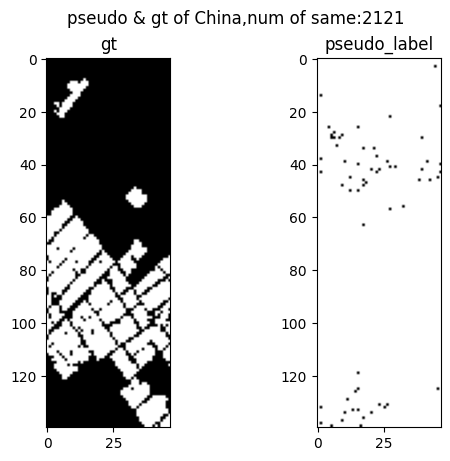

tensor([1, 2])
开始切patch
patch save_dit:./data/data_change/China/
1000 patch已切,1000个patch用时 0.7494025230407715
2000 patch已切,1000个patch用时 0.7154853343963623
3000 patch已切,1000个patch用时 0.707726001739502
4000 patch已切,1000个patch用时 0.8107590675354004
已切完,总用时 3.378272294998169
67IRMAD_China_NewDecision_20%0%
======> start loading the image!
loading dataset,dir = . data/data_change/China
读入真实标签数： 6580 图片高度： 140 图片宽度： 47
数据点总数:4521


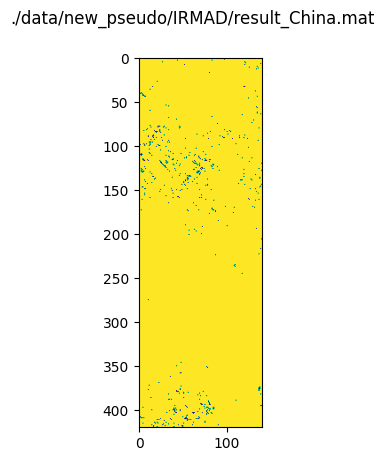

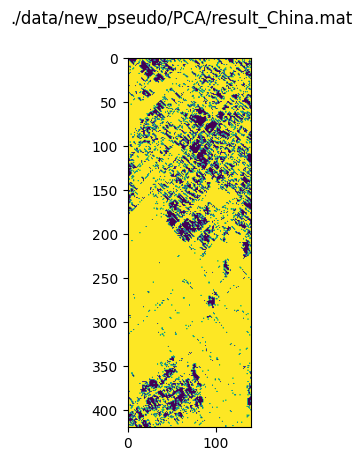

两组伪标签相同的点数： 427 两组伪标签不同的点数： 58373
相同伪标签选20%
T1时刻低分辨率图的大小： torch.Size([1, 154, 140, 47])


RuntimeError: Error(s) in loading state_dict for SSPSR:
	Missing key(s) in state_dict: "trunk.upsample.0.weight", "trunk.upsample.0.bias". 
	Unexpected key(s) in state_dict: "branch.body.net.3.spa.body.0.weight", "branch.body.net.3.spa.body.0.bias", "branch.body.net.3.spa.body.2.weight", "branch.body.net.3.spa.body.2.bias", "branch.body.net.3.spc.body.0.weight", "branch.body.net.3.spc.body.0.bias", "branch.body.net.3.spc.body.2.weight", "branch.body.net.3.spc.body.2.bias", "branch.body.net.3.spc.body.3.conv_du.0.weight", "branch.body.net.3.spc.body.3.conv_du.0.bias", "branch.body.net.3.spc.body.3.conv_du.2.weight", "branch.body.net.3.spc.body.3.conv_du.2.bias", "branch.upsample.0.weight", "branch.upsample.0.bias", "trunk.body.net.3.spa.body.0.weight", "trunk.body.net.3.spa.body.0.bias", "trunk.body.net.3.spa.body.2.weight", "trunk.body.net.3.spa.body.2.bias", "trunk.body.net.3.spc.body.0.weight", "trunk.body.net.3.spc.body.0.bias", "trunk.body.net.3.spc.body.2.weight", "trunk.body.net.

In [105]:
import os
import random
import math
import time
from random import sample
import numpy as np
import scipy.io as sio
# import data.create_data
# import data.create_data_USA
# import nets_5_31 as nets
from torch.optim import Adam
import torch
from torch_geometric.data import Batch
# import graph_matching
# from utils_try import adjust_learning_rate,build_graph_lower,build_graph_upper,build_graph_middle
import matplotlib.pyplot as plt
# from Spatial_SR.common import default_conv
# from Spatial_SR.SSPSR import SSPSR
# from Spectral_SR.model_27 import SpeSRModel
from torch.utils.data import DataLoader,Subset
# from dataset import AllDataset_no_mid as AllDataset
# from HybridLoss import HybridLoss

name_data = 'China'
model = 0
percent = 20
percent2 = 0 # 5
num_renew_pseudo = 10 # 10
num_discard_orginal_label = 50
batch_size = 64
learning_rate = 1e-4
gpu = 'cuda:0'
alpha = 0.3
abstract = str(percent)+'%'+str(percent2)+'%'

if model == 0:
    pic_title = '67IRMAD_' + name_data + '_NewDecision_' + abstract
elif model == 1:
    pic_title = '67IRMAD_' + name_data + '_mid_' + abstract
elif model == 2:
    pic_title = '67IRMAD_' + name_data + '_up_' + abstract
elif model == 3:
    pic_title = '67IRMAD_' + name_data + '_down_' + abstract


# 全局变量
need_cut_data = True                                # 数据预处理

need_Spatial_Super_Resolution = True                 # 空间维超分
need_Spectral_Super_Resolution = True                # 光谱维超分

model_name = '/kaggle/input/c3mgm-hsi-spacial/pytorch/default/1/SSPSR_China.pth'  # 预训练空间超分模型 是这个吗？没用错吗
# model_name_Spectral = './Spectral_SR/pretrained_model/USA_pretrained.pth' # 预训练光谱超分模型 是这个吗？没用错吗
model_name_Spectral = '/kaggle/input/c3mgm-hsi-china/pytorch/default/1/China_pretrained_150 (1).pth' # 预训练光谱超分模型 是这个吗？没用错吗
pseudo_label_dir = './data/new_pseudo/IRMAD/result_China.mat'           # 5.4换伪标签1
pseudo_label_dir2 = './data/new_pseudo/PCA/result_China.mat'           # 5.4换伪标签2
need_save_model = True                              # 是否存模型
lower_pool_or_not = True                             # 下层用27x27还是pool到13x13,默认pool
load_origin_dir2 = '/kaggle/input/csanet/datasets/China2.mat'
load_origin_dir1 = '/kaggle/input/csanet/datasets/China1.mat'
load_origin_dir_gt = '/kaggle/input/csanet/datasets/GTChina.mat'
load_patch_dir = 'data/data_change/' + name_data



np.random.seed(100)
num_process_full_image = 10
epochs = 150
channels = 154
device = torch.device(gpu)
patchsize_HSI = 9
patchsize_PAN = 3 * patchsize_HSI

net_up_size1 = 64  # 上支路第一个MLP的输出尺寸 64 128
net_up_size2 = 128  # 上支路第一个MLP的隐层尺寸 128 256
net_down_size1 = 64 # 下支路第一个CNN的输出尺寸,GCN的输入尺寸 64
mid_hidden_size = 32 # 中路隐层尺寸

def main_cut():
    # 加载T1超分上来的高分高光谱图像（已切patch）和T2的PAN图像（整图）分别构成的patch列表
    if channels == 224:
        list_hs_t1,list_pan_t1,list_mid_t1 = create_HS_list_224(load_origin_dir1, 't1', patchsize_HSI)
        list_hs_t2,list_pan_t2,list_mid_t2 = create_HS_list_224(load_origin_dir2, 't2', patchsize_HSI)
        list_gt,high = create_gt(load_origin_dir2)
        list_pseudo_label = create_pseudo_label_patchwise(pseudo_label_dir)

    # elif name_data == 'USA':
    #     print('USA特供版数据预处理')
    #     list_hs_t1, list_pan_t1, list_mid_t1 = data.create_data_USA.create_HS_list(load_origin_dir, 't1', patchsize_HSI)
    #     list_hs_t2, list_pan_t2, list_mid_t2 = data.create_data_USA.create_HS_list(load_origin_dir, 't2', patchsize_HSI)
    #     list_gt, high = data.create_data_USA.create_gt(load_origin_dir)
    #     list_pseudo_label = data.create_data_USA.create_pseudo_label(pseudo_label_dir)
    else:
        list_hs_t1,list_pan_t1,list_mid_t1 = create_HS_list(load_origin_dir1, 't1', patchsize_HSI)
        list_hs_t2,list_pan_t2,list_mid_t2 = create_HS_list(load_origin_dir2, 't2', patchsize_HSI)
        list_gt,high = create_gt(load_origin_dir_gt)
        list_pseudo_label = create_pseudo_label_patchwise(pseudo_label_dir)


    arr = np.arange(len(list_gt))

    # 打印一下伪标签和真值
    list_pseudo_label_np = np.array(list_pseudo_label)
    list_gt2 = np.array(list_gt)
    if channels == 224:
        num_right = np.count_nonzero((list_gt2 == 1) & (list_pseudo_label_np == 1))
        num_right = num_right + np.count_nonzero((list_gt2 == 2) & (list_pseudo_label_np == 0))
        num_sum = np.count_nonzero(list_gt2==2)
        num_sum = num_sum + np.count_nonzero(list_gt2==1)
        correct = num_right/num_sum
    else:
        correct = np.sum(np.equal(list_gt, list_pseudo_label_np))
    list_pseudo_label_np = np.reshape(list_pseudo_label_np, (high, int(len(list_gt) / high)))
    list_gt2 = np.reshape(list_gt2, (high, int(len(list_gt) / high)))
    fig, axs = plt.subplots(1, 2)
    if channels == 224:
        fig.suptitle('pseudo & gt of ' + name_data + ',num of same:' + str(num_right) + '/' + str(num_sum))
    else:
        fig.suptitle('pseudo & gt of ' + name_data +',num of same:' + str(correct))
    axs[0].imshow(list_gt2, cmap='gray')
    axs[0].set_title('gt')
    axs[1].imshow(list_pseudo_label_np, cmap='gray')
    axs[1].set_title('pseudo_label')
    plt.show()

    list_gt = torch.tensor(list_gt)
    print(torch.unique(list_gt))
    if channels==154:
        list_gt = torch.nn.functional.one_hot(list_gt, 3).type(torch.FloatTensor)
    elif channels == 224:
        list_gt = torch.nn.functional.one_hot(list_gt, 3).type(torch.FloatTensor)
        list_gt[:,[0,1,2]] = list_gt[:,[2,1,0]]
        # 改变后: 0不变 1变 2背景
    else:
        raise Exception('unknown number of channels:',channels,'!!!')

    print('开始切patch')
    print('patch save_dit:./data/data_change/'+name_data+'/')
    time1 = time.time()
    time_all = time.time()
    ii = 0
    for i in range(len(list_gt)):
        if (list_gt.shape[1]==2) or (list_gt.numpy()[i,2] != 1):
            mdict = {'hs_t1':list_hs_t1[i],'hs_t2':list_hs_t2[i],'pan_t1':list_pan_t1[i],'pan_t2':list_pan_t2[i],
                     'gt':list_gt.numpy()[i,:],'arr':arr[i],'pseudo_label':list_pseudo_label[i]}
            os.makedirs('./data/data_change/China', exist_ok=True)
            sio.savemat('./data/data_change/'+name_data+'/'+str(ii)+'.mat',mdict=mdict)
            ii = ii + 1
            if (ii+1)%1000==0:
                print(ii+1,'patch已切,1000个patch用时',time.time()-time1)
                time1 = time.time()
    print('已切完,总用时',time.time()-time_all)

def main():
    global alpha
    print(pic_title)
    mdict_all = {}
    loca = time.strftime('%Y-%m-%d')
    print('======> start loading the image!')
    # 将patch读入dataloader
    all_dataset = AllDataset(load_patch_dir)
    all_dataloader = DataLoader(all_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

    arr_all = []
    for batch, (hs_t1, hs_t2, pan_t1, pan_t2, list_gt, arr, pseudo_label, _) in enumerate(
            all_dataloader):
        for i in arr:
            arr_all.append(i.item())

    print('loading dataset,dir = .', load_patch_dir)
    if name_data == 'USA':
        # gt, height = data.create_data_USA.create_gt(load_origin_dir)
        pass
    else:
        gt, height = create_gt(load_origin_dir_gt)
    width = int(len(gt) / height)
    num_data = len(all_dataset)
    print('数据点总数:{}'.format(num_data))

    # 每轮新增伪标签数
    num_add_label_change = int(num_data/100)
    num_add_label_unchange = int(num_data/100)

    # 读入伪标签
    list_pseudo_label,img_pseudo_label = create_pseudo_label(pseudo_label_dir,need_numpy=True)
    list_pseudo_label2 = create_pseudo_label(pseudo_label_dir2)
    # 杂糅两个伪标签
    pseudo_label_same = []
    pseudo_label_dif = []

    if channels == 154:
        for i in range(len(list_pseudo_label)):
            if list_pseudo_label[i] == list_pseudo_label2[i]:
                pseudo_label_same.append(i)
            else:
                pseudo_label_dif.append(i)
    elif channels == 224:
        datas = sio.loadmat(load_origin_dir_gt)
        Binary = np.array(datas['GT'][...], dtype=np.float32)
        Binary = np.pad(Binary, ((0, 0), (0, 1)), 'symmetric')
        arr_background = []
        for i in range(int(Binary.shape[0] / 3)):
            for j in range(int(Binary.shape[1] / 3)):
                if Binary[i * 3 + 1, j * 3 + 1] == 0:
                    arr_background.append(1)
                else:
                    arr_background.append(0)
        del Binary
        k = 0
        for i in range(len(list_pseudo_label)):
            # if (list_pseudo_label[i] != list_pseudo_label2[i]) & (arr_background[i]==0):
            if (list_pseudo_label[i] == list_pseudo_label2[i]) & (arr_background[i]==0):
                pseudo_label_same.append(k)
                k = k + 1
            elif arr_background[i]==0:
                pseudo_label_dif.append(k)
                k = k + 1
        del arr_background

    del list_pseudo_label, list_pseudo_label2
    img_pseudo_label = np.pad(img_pseudo_label, ((4, 4), (4, 4)), 'symmetric')

    print('两组伪标签相同的点数：',len(pseudo_label_same),'两组伪标签不同的点数：',len(pseudo_label_dif))
    pseudo_label_same = sample(pseudo_label_same,int(len(pseudo_label_same)*(percent/100)))
    subset_a = Subset(all_dataset, pseudo_label_same)
    print('相同伪标签选{}%'.format(percent))
    if percent2 == 0:
        subset = Subset(dataset = all_dataset,indices=pseudo_label_same)
        del subset_a
    else:
        pseudo_label_dif = sample(pseudo_label_dif, int(len(pseudo_label_dif) *(percent2/100)))
        subset_b = Subset(all_dataset, pseudo_label_dif)
        print('不同伪标签选{}%，以准确性高的伪标签为准:'.format(percent2))
        subset = Subset(dataset=all_dataset, indices=pseudo_label_same + pseudo_label_dif)
        print('训练所选取伪标签点总数：{}'.format(len(subset_a) + len(subset_b)))
        del subset_a, subset_b
    sub_dataloader = DataLoader(subset, batch_size=batch_size, shuffle=False, num_workers=4)

    # 读入T1时刻低分
    datas = sio.loadmat(load_origin_dir1)
    img1 = np.array(datas['T1'][...], dtype=np.float32)
    img1 = normalize_data(img1)
    temp = img1[:, :, 0]  # 420x140
    if  name_data == 'USA':
        temp2 = np.pad(temp, ((0, 1), (0, 2)), 'symmetric')
    else:
        temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
    [h_pad, w_pad] = temp2.shape
    img_pad = np.empty((h_pad, w_pad, channels), dtype='float32')
    for i in range(channels):
        temp = img1[:, :, i]
        if name_data == 'USA':
            temp2 = np.pad(temp, ((0, 1), (0, 2)), 'symmetric')
        else:
            temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
        img_pad[:, :, i] = temp2
    img_pad = torch.from_numpy(img_pad).to(device)
    img_pad = torch.permute(img_pad,(2,0,1))
    img_pad = torch.unsqueeze(img_pad,dim=0)
    img_lr = torch.nn.functional.interpolate(img_pad, scale_factor=(1/3, 1/3),mode='bilinear')
    img_lr_upsampling = torch.nn.functional.interpolate(img_lr, scale_factor=(3, 3),mode='bilinear')
    print('T1时刻低分辨率图的大小：',img_lr.shape)

    # 读入T2时刻PAN
    datas = sio.loadmat(load_origin_dir2)
    img2 = np.array(datas['T2'][...], dtype=np.float32)
    img2 = normalize_data(img2)
    temp = img2[:, :, 0]  # 420x140
    if name_data == 'USA':
        temp2 = np.pad(temp, ((0, 1), (0, 2)), 'symmetric')
    else:
        temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
    [h_pad, w_pad] = temp2.shape
    img_pad = np.empty((h_pad, w_pad, channels), dtype='float32')
    for i in range(channels):
        temp = img2[:, :, i]
        if name_data == 'USA':
            temp2 = np.pad(temp, ((0, 1), (0, 2)), 'symmetric')
        else:
            temp2 = np.pad(temp, ((0, 0), (0, 1)), 'symmetric')
        img_pad[:, :, i] = temp2
    if channels == 154:
        img_pan = np.mean(img_pad[:,:,:27], axis=2)
        img_pan = mat2gray(img_pan)
        img_pan = torch.from_numpy(img_pan).to(device)
    else:
        # img_R = np.mean(img_pad[:, :, 0:75], axis=2)
        # img_R = mat2gray(img_R)
        # img_G = np.mean(img_pad[:, :, 75:150], axis=2)
        # img_G = mat2gray(img_G)
        # img_B = np.mean(img_pad[:, :, 150:224], axis=2)
        # img_B = mat2gray(img_B)
        # img_RGB = np.zeros((img_R.shape[0],img_R.shape[1],3))
        # img_RGB[:,:,0] = img_R
        # img_RGB[:,:,1] = img_G
        # img_RGB[:,:,2] = img_B
        # img_RGB = torch.from_numpy(img_RGB).to(device).to(torch.float32).permute(2,0,1).unsqueeze(dim=0)
        img_RGB = np.zeros((img_pad.shape[0], img_pad.shape[1], 3))
        img_RGB[:, :, 0] = img_pad[:, :, 10]
        img_RGB[:, :, 1] = img_pad[:, :, 20]
        img_RGB[:, :, 2] = img_pad[:, :, 35]
        img_RGB = torch.from_numpy(img_RGB).to(device)
        print('T2时刻RGB图的大小：', img_RGB.shape)

    # 图匹配网
    nets_lower = [CNN(net_size1=net_up_size1),GCN(net_size1=net_up_size1),message_net(),MLP(),MLP2(),MLP3()]
    nets_upper = [MLP0(channels=channels, net_size1=net_up_size1,net_size2=net_up_size2),
                  GCNup(patchsize=patchsize_HSI), message_netup(), MLPup(), MLP2up(), MLP3()]
    nets_middle = [
        CNNmid(channel=channels, patchsize=patchsize_HSI, down_size=net_down_size1, out_size=net_up_size1,
                        hidden_size=mid_hidden_size),
        GCNmid(), linear_difference(), linear_classification(),linear_attention()]  # 阿巴阿巴阿巴巴


    # 额外网，用来加入额外标签
    NetsExtra_= NetsExtra().to(device)

    # 空间超分网
    nets_SSPSR = SSPSR(n_subs=8, n_ovls=1, n_colors=channels, n_blocks=3, n_feats=256,
            n_scale=3, res_scale=0.1, use_share=True, conv=default_conv)
    state_dict = torch.load(model_name)
    nets_SSPSR.load_state_dict(state_dict)
    if need_Spatial_Super_Resolution:
        print('use pre_trained SSPSR model name:', model_name)
    nets_SSPSR.to(device)

    # 光谱超分网
    nets_SpeSR = SpeSRModel(input_features=1, output_features=channels)
    state_dict2 = torch.load(model_name_Spectral)
    nets_SpeSR.load_state_dict(state_dict2)

    if need_Spectral_Super_Resolution:
        print('use pre_trained SpeSR model name:', model_name_Spectral)
    nets_SpeSR.to(device)

    # 参数更新
    parameters = []
    parameters_noSR = []
    # 三个图匹配网
    for net in nets_upper:
        net.to(device)
        parameters = parameters + list(net.parameters())
        parameters_noSR = parameters_noSR + list(net.parameters())
    for net in nets_lower:
        net.to(device)
        parameters = parameters + list(net.parameters())
        parameters_noSR = parameters_noSR + list(net.parameters())
    for net in nets_middle:
        net.to(device)
        parameters = parameters + list(net.parameters())
        parameters_noSR = parameters_noSR + list(net.parameters())
    # 两个超分网
    if need_Spatial_Super_Resolution:
        parameters = parameters + list(nets_SSPSR.parameters())
    if need_Spectral_Super_Resolution:
        parameters = parameters + list(nets_SpeSR.parameters())

    # 损失与优化器
    loss_classification = torch.nn.CrossEntropyLoss().to(device)
    # loss_classification = TruncatedLoss(trainset_size=len(all_dataset)).to(device)
    # 4.18 15:01换用新损失    # 4.24换回老损失

    loss_MSE = torch.nn.MSELoss().to(device)
    loss_L1 = torch.nn.L1Loss().to(device)
    # loss_L1 = HybridLoss(spatial_tv=True, spectral_tv=True).to(device)
    optimizer = Adam(parameters , lr=learning_rate, weight_decay=0)
    optimizer_noSR = Adam(parameters_noSR, lr=learning_rate, weight_decay=0)
    optimizer2 = Adam(NetsExtra.parameters(),lr=learning_rate,weight_decay=0)

    accuracy_max = 0

    # 对于每次迭代
    print('============> start training!')
    for e in range(epochs):
        time_begin = time.time()
        print('============> <{}/{}>epoch is beginning'.format(e + 1, epochs))
        adjust_learning_rate(learning_rate, optimizer, e + 1)
        if e == 0:
            arr_append1 = None
            arr_append0 = None

        if ((e + 1) % num_process_full_image == 0) or e == 0:
            process_full_image = True
        else:
            process_full_image = False
        if ((e + 1) >= num_renew_pseudo)&(e < 100):
            renew_pseudo = True
        else:
            renew_pseudo = False

        # 超分结果打印
        # '''
        if process_full_image:
            with torch.no_grad():
                nets_SSPSR.eval()
                nets_SpeSR.eval()
                img_t1_after_sr = nets_SSPSR(img_lr, img_lr_upsampling)
                img_t1_after_sr = torch.squeeze(img_t1_after_sr)

                if e==0:
                    if name_data == 'USA':
                        img_pan = img_pan.cpu().numpy()
                        img_pan = np.pad(img_pan, ((7, 8), (0, 0)), 'symmetric')
                        num_patches_h = img_pan.shape[0] // (patchsize_PAN - 6)
                        num_patches_w = img_pan.shape[1] // (patchsize_PAN - 6)
                    elif name_data == 'China':
                        img_pan = img_pan.cpu().numpy()
                        img_pan = np.pad(img_pan, ((0, 0), (3, 3)), 'symmetric')
                        num_patches_h = img_pan.shape[0] // (patchsize_PAN - 6)
                        num_patches_w = img_pan.shape[1] // (patchsize_PAN - 6)
                    elif name_data == 'Bar':
                        img_RGB = img_RGB.cpu().numpy()
                        img_RGB = np.pad(img_RGB, ((0, 3), (8, 8), (0, 0)), 'symmetric')
                        num_patches_h = img_RGB.shape[0] // (patchsize_PAN - 6)
                        num_patches_w = img_RGB.shape[1] // (patchsize_PAN - 6)
                    else:
                        img_RGB = img_RGB.cpu().numpy()
                        img_RGB = np.pad(img_RGB, ((3, 6), (1, 2), (0, 0)), 'symmetric')
                        num_patches_h = img_RGB.shape[0] // (patchsize_PAN - 6)
                        num_patches_w = img_RGB.shape[1] // (patchsize_PAN - 6)

                # 初始化高光谱和全色 patch 列表
                if channels == 154:
                    img_t2_after_sr = torch.zeros((channels, img_pan.shape[0], img_pan.shape[1])).to(device)
                    for i in range(num_patches_h):
                        for j in range(num_patches_w):
                            # 计算 patch 范围
                            h_start, h_end = i * 21, (i + 1) * 21
                            w_start, w_end = j * 21, (j + 1) * 21
                            # 切分 patch
                            temp = img_pan[h_start:h_end, w_start:w_end]
                            temp = np.pad(temp, ((3, 3), (3, 3),), 'symmetric')
                            temp = torch.from_numpy(temp)
                            pan_patch = temp.unsqueeze(dim=0).unsqueeze(dim=0).to(device).float()
                            # print(pan_patch.shape) # 1x3x27x27
                            pan_patch = nets_SpeSR(pan_patch)[:,:, 3:-3, 3:-3]
                            # print(pan_patch.shape)  # 1x224x21x21
                            img_t2_after_sr[:, h_start:h_end, w_start:w_end] = pan_patch

                elif channels == 224:
                    img_t2_after_sr = torch.zeros((channels, img_RGB.shape[0], img_RGB.shape[1])).to(device)
                    for i in range(num_patches_h):
                        for j in range(num_patches_w):
                            # 计算 patch 范围
                            h_start, h_end = i * 21, (i + 1) * 21
                            w_start, w_end = j * 21, (j + 1) * 21
                            # 切分 patch
                            temp = img_RGB[h_start:h_end, w_start:w_end,:]
                            temp = np.pad(temp, ((3, 3), (3, 3), (0, 0)), 'symmetric')
                            temp = torch.from_numpy(temp)
                            pan_patch = temp.unsqueeze(dim=0).to(device).permute(0, 3, 1, 2).float()
                            # print(pan_patch.shape) # 1x3x27x27
                            pan_patch = nets_SpeSR(pan_patch)[:, :, 3:-3, 3:-3]
                            # print(pan_patch.shape)  # 1x224x21x21
                            img_t2_after_sr[:, h_start:h_end, w_start:w_end] = pan_patch

                if True:
                    # 确认拼接图像尺寸与原图像尺寸一致
                    if name_data == 'USA':
                        img_t2_after_sr = img_t2_after_sr[:, 7:-8, :]
                    elif name_data == 'China':
                        img_t2_after_sr = img_t2_after_sr[:, :, 3:-3]
                    elif name_data == 'Bar':
                        img_t2_after_sr = img_t2_after_sr[:, :-3, 8:-8]
                    else:
                        img_t2_after_sr = img_t2_after_sr[:, 3:-6, 1:-2]

                    image_t1_sr = img_t1_after_sr[(140, 80, 20), :, :].detach().cpu().numpy()
                    image_t1_sr = image_t1_sr.transpose(1, 2, 0)
                    image_t2_sr = img_t2_after_sr[(140, 80, 20), :, :].detach().cpu().numpy()
                    image_t2_sr = image_t2_sr.transpose(1, 2, 0)
                    image_t1_pan = np.mean(image_t1_sr, axis=2)
                    image_t1_pan = mat2gray(image_t1_pan)
                    image_t2_pan = np.mean(image_t2_sr, axis=2)
                    image_t2_pan = mat2gray(image_t2_pan)

                    fig, axs = plt.subplots(1, 4)
                    fig.suptitle('epoch' + str(e + 1) + ', '+pic_title+',show the SR:')
                    axs[0].imshow(image_t1_sr)
                    axs[0].set_title('t1')
                    axs[2].imshow(image_t2_sr)
                    axs[2].set_title('t2')
                    axs[1].imshow(image_t1_pan, cmap='gray')
                    axs[1].set_title('t1_pan')
                    axs[3].imshow(image_t2_pan, cmap='gray')
                    axs[3].set_title('t2_pan')
                    plt.show()
                    # img_t1_after_sr = img_t1_after_sr.detach().cpu().numpy().transpose(1,2,0)
                    # img_t2_after_sr = img_t2_after_sr.detach().cpu().numpy().transpose(1,2,0)
                    # sio.savemat('./result/SR_'+name_data+'-'+str(e+1)+'-'+loca+'.mat',mdict={'t1':img_t1_after_sr,'t2':img_t2_after_sr} )
        # '''
        # 本次迭代内变量
        loss_sum = 0  # 本次迭代总loss
        correct_sum = 0  # 本次迭代总正确分类数
        dif_all = torch.zeros((num_data, 128 * 2))  # 上下路差异向量，用于聚类
        distances = torch.zeros(num_data)  # 中路batch间欧氏距离
        result = np.zeros(height * width)  # 分类结果
        gt_for_show = np.zeros(height * width)  # 用于展示的标签
        gt = np.zeros(height * width)  # 真实标签，用于计算正确率
        # pseudo_labels = np.zeros(num_data)  # 传统算法全图伪标签
        have_label_or_not = torch.zeros(num_data)
        arrs = np.zeros(height * width).astype(int)
        label_for_show = np.zeros((height * width,3)).astype(int)
        preds_all = torch.zeros(num_data)

        # 全图过程：每十轮一次，跑验证，测结果，更新伪标签
        if process_full_image:
            if (e != 0) & (alpha > 0.1):
                alpha = alpha * 0.8
            if alpha < 0.1:
                alpha = 0.1
            print('e', (e + 1), '_alpha:', alpha)
            for net in nets_upper:
                net.eval()
            for net in nets_lower:
                net.eval()
            for net in nets_middle:
                net.eval()
            nets_SSPSR.eval()
            nets_SpeSR.eval()

            with torch.no_grad():
                time_no_loss_begin = time.time()

                for batch, (hs_t1, hs_t2, pan_t1, pan_t2, list_gt, arr, pseudo_label, _) in enumerate(
                        all_dataloader):
                    dif, correct, result, gt_for_show, distances, preds_2 = batch_process(
                        'no_grad', batch, hs_t1, hs_t2, pan_t1, pan_t2,
                        nets_upper, nets_lower, nets_middle, nets_SSPSR, nets_SpeSR,
                        labels=pseudo_label, list_gt=list_gt, arr=arr, result=result, gt=gt_for_show,
                        distances=distances, e=e)

                    # pseudo_labels[batch * batch_size:batch * batch_size + len(hs_t1)] = pseudo_label
                    gt[batch * batch_size:batch * batch_size + len(hs_t1)] = list_gt[:, 1]
                    arrs[batch * batch_size:batch * batch_size + len(hs_t1)] = arr
                    correct_sum = correct_sum + correct
                    preds_all[batch * batch_size:batch * batch_size + len(hs_t1)] = preds_2[:, 0] - preds_2[:, 1]
                    dif_all[batch * batch_size:batch * batch_size + len(hs_t1), :] = dif
                k = int(len(preds_all) * 0.2)
                topk_values, topk_indices = torch.topk(preds_all, k)
                bottomk_values, bottomk_indices = torch.topk(preds_all, k, largest=False)

                print('batch num for no_loss iteration:', batch + 1, '.times:', time.time() - time_no_loss_begin)

                # 构造 have_label_or_not ，如果一个样本在sub_dataloader里，相应位置置1
                have_label_or_not[subset.indices] = 1

            if renew_pseudo:
                time_extra = time.time()
                NetsExtra.train()
                have_label_or_not = have_label_or_not.to(device)
                dif_all = dif_all.to(device)
                for j in range(10):
                    for i in range(math.floor(num_data/batch_size)):
                        a = dif_all[i*batch_size:(i+1)*batch_size,:]
                        a = NetsExtra(a).squeeze()
                        b = have_label_or_not[i*batch_size:(i+1)*batch_size]
                        # loss = loss_MSE(a,b)+loss_L1(a,b)
                        loss = loss_classification(a,b)
                        optimizer2.zero_grad()
                        loss.backward()
                        optimizer2.step()
                NetsExtra.eval()
                dif_all = NetsExtra(dif_all)
                # median = torch.median(dif_all)
                # indices_media = torch.nonzero(torch.lt(dif_all,median))
                dif_sorted_indices = torch.argsort(dif_all).detach().cpu().tolist()
                selected_indices = random.sample(range(len(dif_sorted_indices)),int(len(dif_sorted_indices)/10))
                dif_sorted_indices2 = [dif_sorted_indices[i] for i in sorted(selected_indices)]
                dif_sorted_indices = dif_sorted_indices2
                del dif_sorted_indices2,selected_indices
                top = 0                 # top是0
                bottom = 0              # bottom是1
                top_true = 0
                bottom_true = 0
                top_right = 0
                bottom_right = 0
                arr_append0_pre = []
                arr_append1_pre = []

                for i in dif_sorted_indices:
                    if i in topk_indices:
                        top = top + 1
                        if have_label_or_not[i] == 0 :
                            arr_append0_pre.append(i)
                            top_true = top_true + 1
                            if gt[i] == 0:
                                top_right = top_right + 1
                    if top_true > num_add_label_unchange - 1:
                        break

                for i in dif_sorted_indices:
                    if i in bottomk_indices:
                        bottom = bottom + 1
                        if have_label_or_not[i] == 0 :
                            arr_append1_pre.append(i)
                            bottom_true = bottom_true + 1
                            if gt[i] == 1:
                                bottom_right = bottom_right + 1
                    if bottom_true > num_add_label_change - 1:
                        break

                # a = np.zeros((height * width), dtype=int)
                # b = np.zeros((height * width), dtype=int)
                # c = np.zeros((height * width), dtype=int)
                # for i in arr_append0_pre:
                #     a[arr_all[i]] = 225
                # for i in arr_append1_pre:
                #     b[arr_all[i]] = 255
                # have_label_or_not = have_label_or_not.detach().cpu().numpy().astype(int)
                # for i in range(num_data):
                #     if have_label_or_not[i] == 1:
                #         c[arr_all[i]] = 255
                # a = a.reshape((height, width))
                # b = b.reshape((height, width))
                # c = c.reshape((height, width))
                #
                # fig, axs = plt.subplots(1, 3)
                # plt.suptitle(str(e + 1) + '_new_label')
                # axs[0].imshow(a, cmap='gray')
                # axs[0].set_title('new_0')
                # axs[1].imshow(b, cmap='gray')
                # axs[1].set_title('new_1')
                # axs[2].imshow(c, cmap='gray')
                # axs[2].set_title('old_label')
                # plt.show()
                # del a, b, c, have_label_or_not
                print('<<<<<', e + 1, 'epoch,top:', top, 'top_true:', top_true, 'top_right:', top_right, ',bottom:',
                      bottom, ',bottom_true:', bottom_true, ',bottom_right:', bottom_right, '>>>>>')

                if arr_append1 == None:
                    arr_append1 = []
                    arr_append0 = []
                arr_append0 = arr_append0 + arr_append0_pre
                arr_append1 = arr_append1 + arr_append1_pre
                print('重构前的训练集总长度为：', len(subset))
                if e>=num_discard_orginal_label:
                    subset = Subset(dataset=all_dataset, indices=arr_append0 + arr_append1)
                else:
                    subset = Subset(dataset=all_dataset, indices=subset.indices + arr_append0_pre + arr_append1_pre)
                sub_dataloader = DataLoader(subset, batch_size=batch_size, shuffle=True, num_workers=4,drop_last=True)
                print('重构后的训练集总长度为：',len(subset))

                print('train the extra net need time:', time.time() - time_extra)

            gtgt = np.zeros((height * width))
            for batch2, (hs_t1, hs_t2, pan_t1, pan_t2, list_gt, arr, pseudo_label, index) in enumerate(
                    sub_dataloader):
                for i in range(hs_t1.shape[0]):
                    if list_gt[i, 1] == 1:
                        gtgt[arr[i]] = 1
                    else:
                        gtgt[arr[i]] = 2

        # time_with_loss_begin = time.time()
        for net in nets_upper:
            net.train()
        for net in nets_lower:
            net.train()
        for net in nets_middle:
            net.train()
        nets_SSPSR.train()
        nets_SpeSR.train()

        sum_sum = [0, 0, 0, 0]

        label_true = 0
        label_false = 0
        label_true_new = 0
        label_false_new = 0

        for batch2, (hs_t1, hs_t2, pan_t1, pan_t2, list_gt, arr, pseudo_label, index) in enumerate(sub_dataloader):
            if process_full_image:
                for i in range(hs_t1.shape[0]):
                    if list_gt[i, 1] == pseudo_label[i]:
                        if not renew_pseudo:
                            label_for_show[arr[i], 1] = 255
                        label_true = label_true + 1
                    else:
                        if not renew_pseudo:
                            label_for_show[arr[i], 0] = 255
                        label_false = label_false + 1
                if renew_pseudo:
                    for i in range(hs_t1.shape[0]):
                        if index[i] in arr_append0:
                            if gtgt[arr[i]] == 2:
                                label_for_show[arr[i], 1] = 255
                                label_true_new = label_true_new + 1
                            else:
                                label_for_show[arr[i], 0] = 255
                                label_false_new = label_false_new + 1
                    for i in range(hs_t1.shape[0]):
                        if index[i] in arr_append1:
                            if gtgt[arr[i]] == 1:
                                label_for_show[arr[i], 1] = 255
                                label_for_show[arr[i], 2] = 255
                                label_true_new = label_true_new + 1
                            else:
                                label_for_show[arr[i], 0] = 255
                                label_for_show[arr[i], 2] = 255
                                label_false_new = label_false_new + 1

            loss,Sum = batch_process('with_grad', batch2, hs_t1, hs_t2, pan_t1, pan_t2, nets_upper, nets_lower, nets_middle,
                                     nets_SSPSR, nets_SpeSR,
                                     labels=pseudo_label, list_gt=list_gt, loss_classification=loss_classification, loss_MSE=loss_MSE, loss_L1=loss_L1,
                                     arr=arr, optimizer=optimizer, e=e, arr_append0=arr_append0, arr_append1=arr_append1, index=index, ipl1 = img_pseudo_label)
            loss_sum = loss_sum + loss
            sum_sum[0] = sum_sum[0] + Sum[0]
            sum_sum[1] = sum_sum[1] + Sum[1]
            sum_sum[2] = sum_sum[2] + Sum[2]
            sum_sum[3] = sum_sum[3] + Sum[3]
        # print('batch num for with_loss iteration:', batch2 + 1, '.times:', time.time() - time_with_loss_begin)

        if process_full_image:
            print('新增正确标签{},错误标签{}'.format(label_true_new, label_false_new))
            print('[总计:{},全部一致:{},旧标签错误:{},新标签错误:{},新伪标签都错误:{}]'.format(
                sum_sum[0] + sum_sum[1] + sum_sum[2] + sum_sum[3], sum_sum[0], sum_sum[1], sum_sum[2], sum_sum[3]))
            print('总共正确标签{},错误标签{}'.format(label_true, label_false))
            # 打印结果图
            result = np.reshape(result, (height, width))

            if e > 30:
                img_pseudo_label = np.pad(result, ((4, 4), (4, 4)), 'symmetric')
                img_pseudo_label[img_pseudo_label==0.5] = 0

            gt_for_show = np.reshape(gt_for_show, (height, width))
            label_for_show = np.reshape(label_for_show,(height,width,3))
            accuracy = correct_sum / num_data

            fig, axs = plt.subplots(1, 3)
            fig.suptitle(str(e + 1) + ' ' + pic_title + '\n' + 'accuracy:' + str(correct_sum / num_data))
            axs[0].imshow(gt_for_show, cmap='gray')
            axs[0].set_title(str(e + 1) + ' gt_for_show')
            axs[1].imshow(result, cmap='gray')
            axs[1].set_title(str(e + 1) + ' result')
            axs[2].imshow(label_for_show)
            axs[2].set_title('label' + str(label_true) +'/' + str(label_true+label_false))
            plt.show()

            mdict_all['e'+str(e+1)] = result
            if (e!=0)&(accuracy>0.9):
                if accuracy > accuracy_max:
                    accuracy_max = accuracy
                    e_max = e+1
                print(accuracy_max)
                accu = f'{accuracy:.3f}'

                if (need_save_model == True):
                    dir_save = './save_model/' + name_data + '/' + pic_title + '_' + accu
                    if not os.path.exists(dir_save):
                        os.makedirs(dir_save)
                        os.makedirs(dir_save + '/up')
                        os.makedirs(dir_save + '/low')
                        os.makedirs(dir_save + '/middle')

                    k = 0
                    for net in nets_upper:
                        torch.save(net.state_dict(), dir_save + '/up/' + str(k) + '.pth')
                        k = k + 1
                    k = 0
                    for net in nets_lower:
                        torch.save(net.state_dict(), dir_save + '/low/' + str(k) + '.pth')
                        k = k + 1
                    k = 0
                    for net in nets_middle:
                        torch.save(net.state_dict(), dir_save + '/middle/' + str(k) + '.pth')
                        k = k + 1
                    torch.save(nets_SpeSR.state_dict(), dir_save + '/SpeSR' + '.pth')
                    torch.save(nets_SSPSR.state_dict(), dir_save + '/SSPSR' + '.pth')

                '''
                sio.savemat('./result/'+pic_title+str(batch_size)+'-'+str(e+1)+'-'+accu+'-'+loca+'.mat', mdict = {'result':result})
                '''
            print(
                '<{}/{}>epoch has done,Time for this epoch: {:.2f} seconds,avg loss in this epoch：{:.6f},avg correct in this epoch：{:.6f}'
                .format(e + 1, epochs, time.time() - time_begin, loss_sum / len(sub_dataloader),accuracy))
        else:
            print(
                '<{}/{}>epoch has done,Time for this epoch: {:.2f} seconds,avg loss in this epoch：{:.6f}'
                .format(e + 1, epochs, time.time() - time_begin, loss_sum / len(sub_dataloader)))

    # 保存模型
    '''
    if (need_save_model == True):
        dir_save = './save_model/' + name_data + '/' + pic_title
        os.makedirs(dir_save)
        os.makedirs(dir_save + '/up')
        os.makedirs(dir_save + '/low')
        os.makedirs(dir_save + '/middle')
        k = 0
        for net in nets_upper:
            torch.save(net.state_dict(), dir_save + '/up/' + str(k) + '.pth')
            k = k + 1
        k = 0
        for net in nets_lower:
            torch.save(net.state_dict(), dir_save + '/low/' + str(k) + '.pth')
            k = k + 1
        k = 0
        for net in nets_lower:
            torch.save(net.state_dict(), dir_save + '/middle/' + str(k) + '.pth')
            k = k + 1
        torch.save(nets_SpeSR.state_dict(), dir_save + '/SpeSR' + '.pth')
        torch.save(nets_SSR.state_dict(), dir_save + '/SSPSR' + '.pth')
    '''

    print(accuracy_max)
    accu = f'{accuracy_max:.3f}'
    sio.savemat('./result/result_China/' + pic_title + '-' + str(batch_size) + '-' + str(learning_rate) +'-' +  str(e_max) +'-' + accu + '-' + str(num_renew_pseudo) + '-' + str(num_discard_orginal_label) + '-' + loca + '.mat', mdict = mdict_all)


def batch_process(grad,batch,hs_t1,hs_t2,pan_t1,pan_t2,nets_upper,nets_lower,nets_middle,nets_SSR,nets_SpeSR,
                  labels=None,loss_classification=None,loss_MSE=None,loss_L1=None,optimizer=None,list_gt=None,arr=None,result=None,
                  gt=None,distances=None,e=None,arr_append0=None,arr_append1=None,index=None,ipl1=None):

    global alpha
    # 最后一个batch的batch_num可能会小于batch_size，其余时刻相等
    patch_num = hs_t1.shape[0]

    Sum = [0, 0, 0, 0]

    if grad=='with_grad' and ((arr_append1 is not None)or(arr_append0 is not None)):

        # 我明白啦！我明白啦！我终于明白啦！

        for i in range(len(index)):
            if index[i] in arr_append0:
                if (labels[i] == 0) and (list_gt[i, 1] == 0):
                    Sum[0] = Sum[0] + 1
                elif (labels[i] == 1) and (list_gt[i, 1] == 0):
                    Sum[1] = Sum[1] + 1
                elif (labels[i] == 0) and (list_gt[i, 1] == 1):
                    Sum[3] = Sum[3] + 1
                elif (labels[i] == 1) and (list_gt[i, 1] == 1):
                    Sum[2] = Sum[2] + 1
                labels[i] = 0
            if index[i] in arr_append1:
                if (labels[i] == 1) and (list_gt[i, 1] == 1):
                    Sum[0] = Sum[0] + 1
                elif (labels[i] == 0) and (list_gt[i, 1] == 1):
                    Sum[1] = Sum[1] + 1
                elif (labels[i] == 1) and (list_gt[i, 1] == 0):
                    Sum[3] = Sum[3] + 1
                elif (labels[i] == 0) and (list_gt[i, 1] == 0):
                    Sum[2] = Sum[2] + 1
                labels[i] = 1

    # 上路
    batch_t1_up_no_reshape = hs_t1
    batch_t1_up = torch.reshape(hs_t1,(-1,channels)).to(device)
    # batch_t2_up = torch.reshape(hs_t2,(-1,channels)).to(device)

    # batch_t1_up = torch.reshape(hs_t1[:,1:-1,1:-1,:],(-1,channels)).to(device) # 4.13改 7x7模式
    # batch_t2_up = torch.reshape(hs_t2[:,1:-1,1:-1,:],(-1,channels)).to(device)

    batch_t1_up_no_reshape = torch.permute(batch_t1_up_no_reshape,(0,3,1,2)).to(device)
    batch_up_sampling = torch.nn.functional.interpolate(batch_t1_up_no_reshape, scale_factor=(3, 3), mode='bilinear').to(device)

    # 下路
    if channels == 224:
        # batch_t1_down = pan_t1.to(device).permute(0,3,1,2)
        batch_t2_down = pan_t2.to(device).permute(0,3,1,2)
    else:
        # batch_t1_down = pan_t1.unsqueeze(1).to(device)
        batch_t2_down = pan_t2.unsqueeze(1).to(device)

    # #对T1时刻图像进行空间维超分！！！！！！！！超超超
    # if need_Spatial_Super_Resolution == True:
    batch_t1_mid = nets_SSR(batch_t1_up_no_reshape,batch_up_sampling)
    if channels == 154:
        batch_t1_down = torch.mean(batch_t1_mid, dim=1).unsqueeze(1)
    else:
        batch_t1_down_R = torch.mean(batch_t1_mid[:,0:75,:,:], dim=1).unsqueeze(dim=1)
        batch_t1_down_G = torch.mean(batch_t1_mid[:,75:150,:,:], dim=1).unsqueeze(dim=1)
        batch_t1_down_B = torch.mean(batch_t1_mid[:,150:,:,:], dim=1).unsqueeze(dim=1)
        batch_t1_down = torch.cat((batch_t1_down_R,batch_t1_down_G,batch_t1_down_B),dim=1)

    # #对T2时刻图像进行光谱维超分！！！！！！！！超超超
    # if need_Spectral_Super_Resolution == True:
    batch_t2_mid = nets_SpeSR(batch_t2_down)
    batch_t2_up = torch.nn.functional.interpolate(batch_t2_mid,scale_factor=(1/3,1/3),mode='bilinear')
    batch_t2_up = torch.transpose(batch_t2_up, 1, 0)
    batch_t2_up = torch.reshape(batch_t2_up, (batch_t2_up.shape[0], -1))
    batch_t2_up = torch.transpose(batch_t2_up, 1, 0)

    # 下路CNN/上路MLP
    batch_t1_up_afterCNN = nets_upper[0](batch_t1_up)
    batch_t2_up_afterCNN = nets_upper[0](batch_t2_up)
    batch_t1_down_afterCNN = nets_lower[0](batch_t1_down, lower_pool_or_not)
    batch_t2_down_afterCNN = nets_lower[0](batch_t2_down, lower_pool_or_not)

    batch_t1_up_afterCNN = batch_t1_up_afterCNN.reshape((patch_num, -1, net_up_size1)) # 4.13改
    batch_t2_up_afterCNN = batch_t2_up_afterCNN.reshape((patch_num, -1, net_up_size1))
    # batch_t1_up_afterCNN = batch_t1_up_afterCNN.reshape((patch_num, patchsize_HSI * patchsize_HSI, net_up_size1))
    # batch_t2_up_afterCNN = batch_t2_up_afterCNN.reshape((patch_num, patchsize_HSI * patchsize_HSI, net_up_size1))

    # 每个patch构一张图，每个batch的图构成一个列表
    list_graph_up = []
    list_graph_down = []
    tensor_up_t1 = torch.zeros((patch_num, net_up_size1, patchsize_HSI * patchsize_HSI)).to(device)
    tensor_up_t2 = torch.zeros((patch_num, net_up_size1, patchsize_HSI * patchsize_HSI)).to(device)
    tensor_down_t1 = torch.zeros((patch_num, batch_t1_down_afterCNN.shape[3]*batch_t1_down_afterCNN.shape[3], net_down_size1)).to(device)
    tensor_down_t2 = torch.zeros((patch_num, batch_t1_down_afterCNN.shape[3]*batch_t1_down_afterCNN.shape[3], net_down_size1)).to(device)

    for patch in range(patch_num):
        graph_t1_up = build_graph_upper(batch_t1_up_afterCNN[patch, :, :], device)  # 每patch构一图
        graph_t2_up = build_graph_upper(batch_t2_up_afterCNN[patch, :, :], device)
        list_graph_up.append(graph_t1_up), list_graph_up.append(graph_t2_up)
        tensor_up_t1[patch, :, :] = graph_t1_up.x
        tensor_up_t2[patch, :, :] = graph_t2_up.x
        graph_t1_down = build_graph_lower(batch_t1_down_afterCNN[patch, :, :, :], device)  # 每patch构一图
        graph_t2_down = build_graph_lower(batch_t2_down_afterCNN[patch, :, :, :], device)
        list_graph_down.append(graph_t1_down), list_graph_down.append(graph_t2_down)
        tensor_down_t1[patch, :, :] = graph_t1_down.x
        tensor_down_t2[patch, :, :] = graph_t2_down.x

    batch_graph_up = Batch.from_data_list(list_graph_up).to(device)  # 每batch小图合成大图
    batch_graph_down = Batch.from_data_list(list_graph_down).to(device)  # 每batch小图合成大图

    # 中路CNN、加注意力、构图、GCN
    batch_t1_mid_afterCNN = nets_middle[0](batch_t1_mid, tensor_up_t1, tensor_down_t1, need_attention=True)
    batch_t2_mid_afterCNN = nets_middle[0](batch_t2_mid, tensor_up_t1, tensor_down_t2, need_attention=True)
    graph_t1_mid, A_t1, top_k = build_graph_middle(batch_t1_mid_afterCNN, device)  # 邻接矩阵在图匹配中还要用
    graph_t2_mid, A_t2, _ = build_graph_middle(batch_t2_mid_afterCNN, device)
    graph_t1_mid = graph_t1_mid.to(device)
    graph_t2_mid = graph_t2_mid.to(device)

    # 三路图匹配
    preds_mid, dif_mid, s_diag = graph_matching_middle_new(graph_t1_mid, graph_t2_mid, nets_middle)
    preds_up, dif_up = graph_matching_UPorDOWN_new(batch_graph_up, nets_upper, patch_num, s_diag)
    preds_down, dif_down = graph_matching_UPorDOWN_new(batch_graph_down, nets_lower, patch_num, s_diag)

    if(grad == 'with_grad'):
        # 分类损失
        label = torch.from_numpy(np.eye(2)[labels]).to(device)
        if model == 1:
            loss = loss_classification(preds_mid, label)
        elif model == 2:
            loss = loss_classification(preds_up, label)
        elif model == 3:
            loss = loss_classification(preds_down, label)
        else:
            loss1 = loss_classification(preds_mid, label)
            loss2 = loss_classification(preds_up, label)
            loss3 = loss_classification(preds_down, label)
            loss = loss1 + loss2 + loss3

        # 图像超分损失 5.30改
        num_zeros = 0
        available_points = np.zeros(patch_num)
        # img_show = ipl1[4:-4,4:-4]
        # img_show = img_show/4
        for i in range(patch_num):
            if label[i,0] == 1:
                x_axis = math.floor(index[i]/(ipl1.shape[1]-8))
                y_axis = index[i]%(ipl1.shape[1]-8)
                # img_show[x_axis, y_axis] = 0.5
                if ipl1[x_axis:x_axis + 9, y_axis:y_axis + 9].sum()==0:
                    num_zeros = num_zeros + 1
                    available_points[i] = 1
                    # img_show[x_axis,y_axis] = 1

        if num_zeros != 0:
            batch_t2_up = torch.reshape(batch_t2_up, (patch_num, 9, 9, channels))
            new_t1_mid = torch.zeros(
                (num_zeros, batch_t1_mid.shape[1], batch_t1_mid.shape[2], batch_t1_mid.shape[3])).to(device)
            new_t2_mid = torch.zeros(
                (num_zeros, batch_t1_mid.shape[1], batch_t1_mid.shape[2], batch_t1_mid.shape[3])).to(device)
            if channels == 154:
                new_t1_down = torch.zeros((num_zeros, 27, 27)).to(device)  # 4.13 ???????
                new_pan_t2 = torch.zeros((num_zeros, 27, 27)).to(device)
            else:
                new_t1_down = torch.zeros((num_zeros, 27, 27, 3)).to(device)  # 4.13 ???????
                new_pan_t2 = torch.zeros((num_zeros, 27, 27, 3)).to(device)
            new_hs_t1 = torch.zeros((num_zeros, 9, 9, channels)).to(device)
            new_t2_up = torch.zeros((num_zeros, 9, 9, channels)).to(device)
            num2 = 0
            for num in range(patch_num):
                # if label[num, 1] == 0:
                if available_points[num] == 1:
                    if channels == 224:
                        new_t1_down[num2, :, :, :] = batch_t1_down[num, :, :, :].permute(1, 2, 0)
                        new_pan_t2[num2, :, :, :] = pan_t2[num, :, :, :]
                    else:
                        new_t1_down[num2, :, :] = batch_t1_down[num, 0, :, :]
                        new_pan_t2[num2, :, :] = pan_t2[num, :, :]
                    new_hs_t1[num2, :, :, :] = hs_t1[num, :, :, :]
                    new_t2_up[num2, :, :, :] = batch_t2_up[num, :, :, :]
                    new_t1_mid[num2, :, :, :] = batch_t1_mid[num, :, :, :]
                    new_t2_mid[num2, :, :, :] = batch_t2_mid[num, :, :, :]
                    num2 = num2 + 1

            # 打印超分结果图
            if (batch == 0) & (((e + 1) % 10 == 0) or (e == 0)):
                new_hs_t1_show = new_hs_t1[0, :, :, (10, 20, 35)].detach().cpu().numpy()
                new_t2_up_show = new_t2_up[0, :, :, (10, 20, 35)].detach().cpu().numpy()
                new_t1_down_show = new_t1_down[0, :, :].detach().cpu().numpy()
                new_pan_t2_show = new_pan_t2[0, :, :].detach().cpu().numpy()
                image_t1_sr = new_t1_mid[0, (10, 20, 35), :, :].detach().cpu().numpy()
                image_t1_sr = image_t1_sr.transpose(1, 2, 0)
                image_t2_sr = new_t2_mid[0, (10, 20, 35), :, :].detach().cpu().numpy()
                image_t2_sr = image_t2_sr.transpose(1, 2, 0)

                fig, axs = plt.subplots(2, 3)
                fig.suptitle(name_data + '_epoch:' + str(e + 1) + ',batch:' + str(batch))
                # 显示第1个图像
                axs[0, 0].imshow(new_hs_t1_show)
                axs[0, 0].set_title('t1_input')
                # 显示第2个图像
                axs[1, 0].imshow(new_t2_up_show)
                axs[1, 0].set_title('t2_up')
                # 显示第3个图像
                axs[0, 1].imshow(new_t1_down_show)
                axs[0, 1].set_title('t1_down')
                # 显示第4个图像
                axs[1, 1].imshow(new_pan_t2_show)
                axs[1, 1].set_title('t2_input')
                # 显示第5个图像
                axs[0, 2].imshow(image_t1_sr)
                axs[0, 2].set_title('t1_sr')
                # 显示第6个图像
                axs[1, 2].imshow(image_t2_sr)
                axs[1, 2].set_title('t2_sr')
                plt.show()

            loss_guangpu = loss_L1(new_t2_up,new_hs_t1)
            loss_kongjian = loss_L1(new_pan_t2,new_t1_down)
            loss_double_rs = loss_L1(batch_t1_mid, batch_t2_mid)
            # if e<end_renew_SR:
            #     loss = loss*0.02 + loss_kongjian + loss_guangpu + loss_double_rs*0.2
            # else:
            #     loss = loss + loss_kongjian*0.1 + loss_guangpu*0.1 + loss_double_rs*0.02


            loss = loss*(1-3*alpha) + loss_kongjian*alpha  + loss_guangpu*alpha + loss_double_rs*alpha




        # 损失反向传播与优化器更新
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        return loss,Sum

    elif grad == 'no_grad':
        # 上下路差异向量
        dif = torch.cat((dif_up, dif_down,dif_mid), dim=1)

        # 三路预测向量
        if model == 1:
            preds_final = preds_mid
        elif model == 2:
            preds_final = preds_up
        elif model == 3:
            preds_final = preds_down
        else:
            preds_final = (preds_down + preds_up + preds_mid) / 3
        _, predicted_complex = torch.max(preds_final, 1)
        label_gt = list_gt.to(device)
        # 准确率
        correct = (predicted_complex == label_gt[:, 1]).sum().item()

        for num in range(label_gt.shape[0]):
            if (predicted_complex[num] == 0):
                result[arr[num]] = 0.5
            else:
                result[arr[num]] = 1
            if (label_gt[num, 1] == 0):
                gt[arr[num]] = 0.5
            else:
                gt[arr[num]] = 1

        batch_t1_mid = batch_t1_mid.reshape(patch_num,-1)
        batch_t1_mid = batch_t1_mid / torch.norm(batch_t1_mid,dim=0,keepdim=True)
        batch_t2_mid = batch_t2_mid.reshape(patch_num,-1)
        batch_t2_mid = batch_t2_mid / torch.norm(batch_t2_mid,dim=0,keepdim=True)
        distance = torch.sqrt(torch.sum((batch_t1_mid - batch_t2_mid) ** 2, dim=1))

        # 中路欧氏距离向量
        distances[(batch * batch_size):(batch * batch_size + patch_num)] = distance
        return dif,correct,result,gt,distances,preds_final


if need_cut_data:
    main_cut()

main()
